## Pre-processing Data

In [6]:
from matplotlib import pyplot as plt
import numpy as np
import os
import pandas as pd
import seaborn as sns

CURRENT_RESULT_PATH = "/mnt/dados02/" + os.environ['USER'] + "/sampling/data/KuaiRec/result/2026-02-26 00:00/2026-02-26 00:00_{}.parquet"
CURRENT_TRAIN_PATH = "/mnt/dados02/" + os.environ['USER'] + "/sampling/data/KuaiRec/train/interactions.csv"
CURRENT_TEST_PATH =  "/mnt/dados02/" + os.environ['USER'] + "/sampling/data/KuaiRec/valid/interactions.csv"
METRIC_NAME = "ndcg@100"

NUM_RUNS = 50

def unique(sequence):
    seen = set()
    return [x for x in sequence if not (x in seen or seen.add(x))]

### Loading

In [7]:
df_by_bias_type = {}
bias_types = ["random", "marpop", "marpos"]

def get_recname(c):
    try:
        return c[0:c.index("-test")].split(":")[1]
    except ValueError:
        return None

for bias_type in bias_types:
    results_file = CURRENT_RESULT_PATH.format(bias_type)
    if not os.path.exists(results_file): continue
    base_df = pd.read_parquet(results_file)

    if "rating" in base_df.columns:
        base_df["sum_rating"] = base_df["rating"].apply(sum).astype("int32")
    if "sum_rating" in base_df.columns:
        base_df = base_df.query("sum_rating > 0")
    if "pscore" in base_df.columns:
        base_df.drop(["pscore"], axis=1, inplace=True)

    base_df["result_key"] = base_df["result_key"].str.replace(r'_seed\d+', '', regex=True).astype("category")
    base_df["evaluation"] = base_df["evaluation"].apply(
        lambda x: x.get(METRIC_NAME) if isinstance(x, dict) else x
    )

    # Discover all unique recs
    all_keys = base_df["result_key"].unique()
    all_recs = sorted(list(set([get_recname(k) for k in all_keys if get_recname(k) is not None])))

    run_id = 0
    list_df = []
    np.random.seed(42)
    seen_combinations = set()
    while len(seen_combinations) < NUM_RUNS:
        # Generate combination: vary how many and which models
        # run_id = 0 uses all recommenders
        num_recs_to_select = np.random.randint(2, len(all_recs) + 1) if run_id > 0 else len(all_recs)
        selected_recs = np.random.choice(all_recs, size=num_recs_to_select, replace=False)

        # Sort the selection and convert to a tuple so it can be hashed in a set
        combo_key = tuple(sorted(selected_recs))

        if combo_key in seen_combinations:
            continue
        seen_combinations.add(combo_key)

        # Filter base dataframe for only the selected recs
        mask = base_df["result_key"].apply(lambda k: get_recname(k) in selected_recs)

        df_run = base_df[mask].copy()
        df_run["run_id"] = np.int16(run_id)
        list_df.append(df_run)

        run_id += 1

    df_by_bias_type[bias_type] = pd.concat(list_df)

print(df_by_bias_type.keys())
df_by_bias_type[bias_type].head()

dict_keys(['random', 'marpop', 'marpos'])


,imprID,userID,evaluation,size_candidates,sum_rating,result_key,run_id
0,14,14,0.0982,1133,133,train:sar-cosine_full-test_marpos30:sar-cosine...,0
1,19,19,0.2212,1036,36,train:sar-cosine_full-test_marpos30:sar-cosine...,0
2,21,21,0.1076,1099,99,train:sar-cosine_full-test_marpos30:sar-cosine...,0
3,23,23,0.2957,1311,311,train:sar-cosine_full-test_marpos30:sar-cosine...,0
4,24,24,0.1641,1251,251,train:sar-cosine_full-test_marpos30:sar-cosine...,0


### Hardness Classification

In [8]:
train_df = pd.read_csv(CURRENT_TRAIN_PATH)
test_df = pd.read_csv(CURRENT_TEST_PATH)
user_history = (
    train_df
    .merge(test_df[["user_id"]].drop_duplicates(), on=["user_id"], how="inner")
    .rename({"user_id": "userID"}, axis=1)
    .groupby("userID")["video_id"]
    .nunique()
    .to_frame("n_items")
)

user_history["difficulty_group"] = pd.qcut(user_history["n_items"], q=2, labels=["Low", "High"])
user_history.head()

/tmp/ipykernel_3897874/3691334003.py:2: DtypeWarning: Columns (4) have mixed types. Specify dtype option on import or set low_memory=False.
  test_df = pd.read_csv(CURRENT_TEST_PATH)


,n_items,difficulty_group
userID,,
14,368,High
19,335,Low
21,346,Low
23,297,Low
24,337,Low


In [9]:
full_exp_df = (
    df_by_bias_type["random"].query("run_id == 0")
    .query("result_key.str.contains('test_random0')")
    .query("result_key.str.contains('CNCFULL')")
)
user_hardness = full_exp_df.groupby("userID").agg({"evaluation": "mean"})
user_hardness["difficulty_group"] = pd.qcut(
    1 - user_hardness["evaluation"], q=4, labels=["Easy", "Medium", "Hard", "Very Hard"]
)
user_hardness.head()

,evaluation,difficulty_group
userID,,
14,0.150800,Very Hard
19,0.255100,Easy
21,0.138267,Very Hard
23,0.203817,Medium
24,0.144592,Very Hard


### Merging

In [10]:
df_by_biastype_metric_biasmodel_sampler = {}
available_metrics = [METRIC_NAME]
samplers = None
bias_models = None
recs = None

def extract_recname(c):
    return c[0:c.index("-test")].split(":")[1]

for bias_type, df in df_by_bias_type.items():
    df_byline = df.pivot(index=["run_id", "userID"], columns="result_key", values="evaluation")

    # available_metrics = list(df_byline.iloc[0,0].keys())
    samplers = sorted({c.split("_")[-1] for c in df_byline.columns})
    bias_models = sorted({c[c.index("test_")+5: c.rindex(":")] for c in df_byline.columns})
    recs = sorted({extract_recname(c) for c in df_byline.columns})

    df_by_biastype_metric_biasmodel_sampler[bias_type] = {}
    for metric in available_metrics:

        df_by_biastype_metric_biasmodel_sampler[bias_type][metric] = {}
        df_single_metric = df_byline.map(
            lambda r: r.get(metric) if isinstance(r, dict) else r
        ).astype(float)
        for bias in bias_models:
            for sampler in samplers:
                rel_cols = [c for c in df_single_metric.columns if c.split("_")[-1] == sampler and f"test_{bias}" in c]

                # Drop rows only if ALL models are NaN for that run_id
                df_single_metric_sampler = df_single_metric.loc[:, rel_cols].dropna(how="all")
                df_single_metric_sampler.rename(lambda c: extract_recname(c), axis=1, inplace=True)

                # Keep only valid columns
                exist_recs = [r for r in recs if r in df_single_metric_sampler.columns]
                df_single_metric_sampler = df_single_metric_sampler[exist_recs]

                df_single_metric_sampler["biastype"] = bias_type
                df_single_metric_sampler["metric"] = metric
                df_single_metric_sampler["bias"] = bias
                df_single_metric_sampler["sampler"] = sampler

                df_by_biastype_metric_biasmodel_sampler[bias_type][metric].setdefault(bias, {})
                df_by_biastype_metric_biasmodel_sampler[bias_type][metric][bias][sampler] = df_single_metric_sampler


print(available_metrics)
print(samplers)
print(recs)

df_by_biastype_metric_biasmodel_sampler[bias_type][metric][bias][sampler].head()

['ndcg@100']
['CNCFULL', 'CNCRANDEXPO', 'CNCRANDOM@0', 'CNCRANDOM@1', 'CNCRANDOM@10', 'CNCRANDOM@100', 'CNCRANDOM@1000', 'CNCRANDOM@2', 'CNCRANDOM@20', 'CNCRANDOM@200', 'CNCRANDOM@5', 'CNCRANDOM@50', 'CNCRANDOM@500', 'EXPOSED', 'POPULARITY@1', 'POPULARITY@10', 'POPULARITY@100', 'POPULARITY@1000', 'POPULARITY@2', 'POPULARITY@20', 'POPULARITY@200', 'POPULARITY@5', 'POPULARITY@50', 'POPULARITY@500', 'POSITIVITY@1', 'POSITIVITY@10', 'POSITIVITY@100', 'POSITIVITY@1000', 'POSITIVITY@2', 'POSITIVITY@20', 'POSITIVITY@200', 'POSITIVITY@5', 'POSITIVITY@50', 'POSITIVITY@500', 'SKEW@1', 'SKEW@10', 'SKEW@100', 'SKEW@1000', 'SKEW@2', 'SKEW@20', 'SKEW@200', 'SKEW@5', 'SKEW@50', 'SKEW@500', 'WTD@1', 'WTD@10', 'WTD@100', 'WTD@1000', 'WTD@2', 'WTD@20', 'WTD@200', 'WTD@5', 'WTD@50', 'WTD@500', 'WTDH@1', 'WTDH@10', 'WTDH@100', 'WTDH@1000', 'WTDH@2', 'WTDH@20', 'WTDH@200', 'WTDH@5', 'WTDH@50', 'WTDH@500']
['als_full', 'bpr_full', 'clickpop_full', 'ease_full', 'fastai_full', 'lightfm_full', 'lightfmf_full',

result_key     als_full  bpr_full  clickpop_full  ease_full  fastai_full  \
run_id userID                                                              
0      14        0.2975    0.0355         0.4911     0.3492       0.4540   
       19        0.7397    0.0310         0.7322     0.8026       0.7773   
       21        0.2712    0.0000         0.8343     0.5454       0.7080   
       23        0.3107    0.0000         0.6027     0.1964       0.0992   
       24        0.6082    0.0000         0.7678     0.5820       0.4852   

result_key     lightfm_full  lightfmf_full  lightgcn_full  random_full  \
run_id userID                                                            
0      14            0.0000         0.3233         0.5188       0.2173   
       19            0.1060         0.0299         0.8167       0.0000   
       21            0.0386         0.1448         0.8710       0.1329   
       23            0.1094         0.0624         0.6147       0.1629   
       24            0.0256         0.0818         0.6751       0.1021   

result_key     sar-cosine_full  sar-jaccard_full  sasrec_full biastype  \
run_id userID                                                            
0      14               0.2034            0.1048       0.0544   marpos   
       19               0.5300            0.5875       0.0918   marpos   
       21               0.3814            0.3321       0.0677   marpos   
       23               0.6526            0.5588       0.2223   marpos   
       24               0.3780            0.4335       0.1402   marpos   

result_key       metric      bias   sampler  
run_id userID                                
0      14      ndcg@100  marpos95  WTDH@500  
       19      ndcg@100  marpos95  WTDH@500  
       21      ndcg@100  marpos95  WTDH@500  
       23      ndcg@100  marpos95  WTDH@500  
       24      ndcg@100  marpos95  WTDH@500

In [11]:
# Add Ground Thruth (aka GT)
for bias_type, df_by_metric_biasmodel_sampler in df_by_biastype_metric_biasmodel_sampler.items():
    for metric, df_by_biasmodel_sampler in df_by_metric_biasmodel_sampler.items():
        gt_df = None
        for bias, df_by_sampler in df_by_biasmodel_sampler.items():
            if "".join([c for c in bias if c.isdigit()]) == "0":
                gt_df = df_by_sampler["CNCFULL"].copy()
                gt_df["sampler"] = "GT"
                break
        for bias, df_by_sampler in df_by_biasmodel_sampler.items():
            df_by_biastype_metric_biasmodel_sampler[bias_type][metric][bias]["GT"] = gt_df

### Support Variables

In [12]:
samplers_blocks = {}
for sampler in samplers:
    if "@" in sampler:
        sampler_key = sampler.split("@")[0]
        if sampler_key not in samplers_blocks:
            samplers_blocks[sampler_key] = []
        samplers_blocks[sampler_key].append(sampler)

general_samplers = ["CNCFULL", "CNCRANDEXPO", "EXPOSED", "GT"]

for sampler_key, samplers_order in samplers_blocks.items():
    samplers_blocks[sampler_key] = dict(zip(
        sorted(samplers_order, key=lambda x: int(x.split("@")[-1])),
        list(range(len(samplers_order)))
    ))
    samplers_blocks[sampler_key].update(
        {s: len(samplers_order) + i for i, s in enumerate(general_samplers)}
    )

all_samplers_order = {}
size_last_sampler = 0
for i, (sampler_block, sampler_order) in enumerate(samplers_blocks.items()):
    for j, sampler in enumerate(sampler_order):
        all_samplers_order[sampler] = i * size_last_sampler + j
    size_last_sampler = len(sampler_order)

samplers_blocks

{'CNCRANDOM': {'CNCRANDOM@0': 0,
  'CNCRANDOM@1': 1,
  'CNCRANDOM@2': 2,
  'CNCRANDOM@5': 3,
  'CNCRANDOM@10': 4,
  'CNCRANDOM@20': 5,
  'CNCRANDOM@50': 6,
  'CNCRANDOM@100': 7,
  'CNCRANDOM@200': 8,
  'CNCRANDOM@500': 9,
  'CNCRANDOM@1000': 10,
  'CNCFULL': 11,
  'CNCRANDEXPO': 12,
  'EXPOSED': 13,
  'GT': 14},
 'POPULARITY': {'POPULARITY@1': 0,
  'POPULARITY@2': 1,
  'POPULARITY@5': 2,
  'POPULARITY@10': 3,
  'POPULARITY@20': 4,
  'POPULARITY@50': 5,
  'POPULARITY@100': 6,
  'POPULARITY@200': 7,
  'POPULARITY@500': 8,
  'POPULARITY@1000': 9,
  'CNCFULL': 10,
  'CNCRANDEXPO': 11,
  'EXPOSED': 12,
  'GT': 13},
 'POSITIVITY': {'POSITIVITY@1': 0,
  'POSITIVITY@2': 1,
  'POSITIVITY@5': 2,
  'POSITIVITY@10': 3,
  'POSITIVITY@20': 4,
  'POSITIVITY@50': 5,
  'POSITIVITY@100': 6,
  'POSITIVITY@200': 7,
  'POSITIVITY@500': 8,
  'POSITIVITY@1000': 9,
  'CNCFULL': 10,
  'CNCRANDEXPO': 11,
  'EXPOSED': 12,
  'GT': 13},
 'SKEW': {'SKEW@1': 0,
  'SKEW@2': 1,
  'SKEW@5': 2,
  'SKEW@10': 3,
  'SKEW@2

## Meta Evaluation

### Support Functions

In [13]:
def format_sampler_name(c, return_at=False):
    if not return_at:
        c = c.split("@")[0]

    c = c.split("-")[-1].replace("CNC", "").capitalize()
    if c.startswith("Random"):
        c = "Random@$n$"
    if c.startswith("Randexpo"):
        c = "Random@$e$"
    if c == "Gt":
        c = "GT"
    if c.startswith("Wtd"):
        c = c.upper() + "@$n$"
    if c.startswith("Pop"):
        c = "Popularity@$n$"
    if c.startswith("Pos"):
        c = "Positivity@$n$"
    if c.startswith("Skew"):
        c = "Skew@$n$"

    if "@" in c and return_at:
        c = c.split("@")[0] + "@" + c.split("@")[-1]
    return c


def sort_legend(handle, labels):
    expected_order = {
        "GT": 0, "Full": 1, "Exposed": 2,
        "Random@$e$": 3, "Random@$n$": 4,
        "Popularity@$n$": 5, "Positivity@$n$": 6,
        "Skew@$n$": 7, "WTD@$n$": 8, "WTDH@$n$": 9
    }
    sorted_indices = sorted(
        range(len(labels)),
        key=lambda i: expected_order.get(labels[i], len(expected_order))
    )
    return (
        [handle[i] for i in sorted_indices],
        [labels[i] for i in sorted_indices]
    )


def plot_sampler_grid(
    data_by_biastype_metric_bias_samplerblock,
    *,
    bias_types,
    available_metrics,
    metric_name,
    samplers_blocks,
    percentages_to_plot,
    value_col_name,          # e.g. "tie_rate", "kendall", etc. (used only for clarity)
    yscale=None,             # e.g. "log" or None
    ylim=None,               # e.g. (0.0001, 0.55)
    figsize=(22, 8),
    default_cols=("CNCFULL", "EXPOSED", "CNCRANDEXPO"),
    output_path=None,
    filename=None
):
    """
    Generic function to plot a grid of sampler-vs-n line plots.

    Expected input structure:
        data_by_biastype_metric_bias_samplerblock
            [biastype][metric][bias][sampler_block] -> DataFrame
                columns = samplers
                rows    = repetitions / seeds

    The function reconstructs a long-format DataFrame compatible with seaborn.lineplot.
    """

    plt.rcParams.update({'font.size': 16})
    sns.color_palette("Set2", n_colors=9)

    fig, axes = plt.subplots(
        nrows=len(bias_types),
        ncols=len(percentages_to_plot),
        figsize=figsize
    )

    handles, labels = None, None

    for i, biastype in enumerate(bias_types):
        list_plotdfs = []

        for metric in available_metrics:
            if metric != metric_name:
                continue

            metric_dict = (
                data_by_biastype_metric_bias_samplerblock
                .get(biastype, {})
                .get(metric, {})
            )

            if not metric_dict:
                continue

            for sampler_block in samplers_blocks:
                list_biasdfs = []

                for bias, df_by_samplerblock in metric_dict.items():
                    # Filter only selected sparsity percentages
                    pct = int("".join(c for c in bias if c.isdigit()))
                    if pct not in percentages_to_plot:
                        continue

                    df = df_by_samplerblock[sampler_block].copy()
                    df["bias"] = bias
                    list_biasdfs.append(df)

                if not list_biasdfs:
                    continue

                df_aux = pd.concat(list_biasdfs)

                # Calculate average over users for each run_id
                df_aux = df_aux.groupby([df_aux.index.get_level_values("run_id"), "bias"]).mean().reset_index()

                # Keep FULL / EXPOSED / RANDEXPO only for RANDOM blocks
                select_cols = list(default_cols) if "RANDOM" in sampler_block else []
                sampler_cols = [c for c in df_aux.columns if c not in ["bias", "run_id"]]
                select_cols.extend([c for c in sampler_cols if c not in select_cols])

                # Keep "bias" and "run_id" in the melt operation
                df_aux = (
                    df_aux[select_cols + ["bias", "run_id"]]
                    .melt(id_vars=["bias", "run_id"], var_name="sampler", value_name=value_col_name)
                )

                # Pivot using "run_id" to calculate averages of averages
                df_aux = (
                    df_aux
                    .pivot(index=["sampler", "run_id"], columns="bias", values=value_col_name)
                    .reset_index(level="run_id", drop=True)
                )

                df_aux.columns.name = None
                df_aux.index.name = None

                # Prefix metric name to keep compatibility with original plotting code
                list_plotdfs.append(
                    df_aux.rename(lambda c: metric + "-" + c, axis=0)
                )

        if not list_plotdfs:
            continue

        df_plot = pd.concat(list_plotdfs)

        # --- Extract sampler name and @n value ---
        df_plot["sampler"] = df_plot.index.str.split("-").str[-1]
        df_plot["at"] = df_plot["sampler"].apply(
            lambda s: int(s.split("@")[-1]) if "@" in s else -1
        )

        # Replicate samplers without @n across all n values
        no_at = df_plot[df_plot["at"] == -1].copy()
        df_plot = df_plot[df_plot["at"] != -1].copy()

        for at in df_plot["at"].unique():
            aux = no_at.copy()
            aux["at"] = at
            df_plot = pd.concat([df_plot, aux])

        # Format sampler names (latex + canonical names)
        df_plot["sampler"] = df_plot["sampler"].apply(format_sampler_name)
        df_plot = df_plot.query("sampler != 'GT'")
        df_plot = df_plot.sort_values("sampler").reset_index(drop=True)

        # --- Row label (logger / bias type) ---
        grid_label = "".join(c for c in biastype if not c.isdigit()).capitalize()
        if grid_label == "Marpos":
            grid_label = "Positivity"
        if grid_label == "Marpop":
            grid_label = "Popularity"
        if grid_label == "Random":
            grid_label = "Uniform"

        # --- Plot each sparsity column ---
        for j, p in enumerate(percentages_to_plot):
            ax = axes[i][j]

            ax = sns.lineplot(df_plot, x="at", y=f"{biastype}{p}", hue="sampler", ax=ax)

            if ylim is not None:
                ax.set_ylim(*ylim)

            if yscale is not None:
                ax.set_yscale(yscale)

            if i == 0:
                ax.set_title(f"{p}%", fontsize=16)

            if i != len(bias_types) - 1:
                ax.set_xticklabels([])
                ax.xaxis.set_tick_params(length=0)
            else:
                ax.set_xlabel("")

            if j == 0:
                ax.set_ylabel(grid_label, fontsize=16)
            else:
                ax.set_ylabel("")
                ax.set_yticklabels([])
                ax.yaxis.set_tick_params(length=0)

            handles, labels = ax.get_legend_handles_labels()
            ax.legend_.remove()

    # --- Global legend ---
    fig.legend(
        *sort_legend(handles, labels),
        loc="upper center",
        bbox_to_anchor=(0.5, -0.01),
        ncol=len(handles),
        frameon=False,
        fontsize=16
    )

    fig.tight_layout(w_pad=0.3, h_pad=0.3)

    # --- Global axis labels ---
    fig.text(0.5, 1.01, "Sparsity", ha="center", fontsize=16)
    fig.text(0.5, 0.0, "Sample Size ($n$)", ha="center", fontsize=16)
    fig.text(0.0, 0.5, "Logger", va="center", rotation="vertical", fontsize=16)

    # --- Save figure ---
    if output_path is not None and filename is not None:
        fig.savefig(
            os.path.join(output_path, filename),
            dpi=1300,
            bbox_inches="tight",
            pad_inches=0.05
        )

    fig.show()

In [14]:
def plot_sampler_grid_with_hardness(
    data_by_biastype_metric_bias_samplerblock,
    *,
    bias_types,
    available_metrics,
    metric_name,
    samplers_blocks,
    percentages_to_plot,
    value_col_name,
    yscale=None,
    ylim=None,
    figsize=(22, 8),
    default_cols=("CNCFULL", "EXPOSED", "CNCRANDEXPO"),
    user_hardness=None,
    output_path=None,
    filename=None
):
    """
    Generic function to plot a grid of sampler-vs-n line plots.

    Expected input structure:
        data_by_biastype_metric_bias_samplerblock
            [biastype][metric][bias][sampler_block] -> DataFrame
                columns = samplers
                rows    = repetitions / seeds

        user_hardness:
            None OR DataFrame with columns:
                - index or column matching df.index (e.g., user_id)

    The function reconstructs a long-format DataFrame compatible with seaborn.lineplot.
    """

    plt.rcParams.update({'font.size': 16})
    sns.color_palette("Set2", n_colors=9)

    # --------------------------------------------------
    # Decide how many figures we will plot
    # --------------------------------------------------
    if user_hardness is None:
        category_iter = [(None, None)]
    else:
        category_iter = [
            (cat, user_hardness[user_hardness["difficulty_group"] == cat])
            for cat in user_hardness["difficulty_group"].cat.categories
        ]

    for category_name, hardness_df in category_iter:

        fig, axes = plt.subplots(
            nrows=len(bias_types),
            ncols=len(percentages_to_plot),
            figsize=figsize
        )

        handles, labels = None, None

        for i, biastype in enumerate(bias_types):
            list_plotdfs = []

            for metric in available_metrics:
                if metric != metric_name:
                    continue

                metric_dict = (
                    data_by_biastype_metric_bias_samplerblock
                    .get(biastype, {})
                    .get(metric, {})
                )

                if not metric_dict:
                    continue

                for sampler_block in samplers_blocks:
                    list_biasdfs = []

                    for bias, df_by_samplerblock in metric_dict.items():
                        pct = int("".join(c for c in bias if c.isdigit()))
                        if pct not in percentages_to_plot:
                            continue

                        df = df_by_samplerblock[sampler_block].copy()

                        # --------------------------------------------------
                        # Filter by hardness category
                        # --------------------------------------------------
                        if hardness_df is not None:
                            df = df[df.index.get_level_values("userID").isin(hardness_df.index)]

                        df["bias"] = bias
                        list_biasdfs.append(df)

                    if not list_biasdfs:
                        continue

                    df_aux = pd.concat(list_biasdfs)

                    df_aux = df_aux.groupby([df_aux.index.get_level_values("run_id"), "bias"]).mean().reset_index()

                    select_cols = list(default_cols) if "RANDOM" in sampler_block else []
                    # Ensure we drop run_id and bias from sampler cols before melting
                    sampler_cols = [c for c in df_aux.columns if c not in ["bias", "run_id"]]
                    select_cols.extend([c for c in sampler_cols if c not in select_cols])

                    # Keep "bias" and "run_id" in the melt operation
                    df_aux = (
                        df_aux[select_cols + ["bias", "run_id"]]
                        .melt(id_vars=["bias", "run_id"], var_name="sampler", value_name=value_col_name)
                    )

                    # Pivot using "run_id"
                    df_aux = (
                        df_aux
                        .pivot(index=["sampler", "run_id"], columns="bias", values=value_col_name)
                        .reset_index(level="run_id", drop=True)
                    )

                    df_aux.columns.name = None
                    df_aux.index.name = None

                    list_plotdfs.append(
                        df_aux.rename(lambda c: metric + "-" + c, axis=0)
                    )

            if not list_plotdfs:
                continue

            df_plot = pd.concat(list_plotdfs)

            df_plot["sampler"] = df_plot.index.str.split("-").str[-1]
            df_plot["at"] = df_plot["sampler"].apply(
                lambda s: int(s.split("@")[-1]) if "@" in s else -1
            )

            no_at = df_plot[df_plot["at"] == -1].copy()
            df_plot = df_plot[df_plot["at"] != -1].copy()

            for at in df_plot["at"].unique():
                aux = no_at.copy()
                aux["at"] = at
                df_plot = pd.concat([df_plot, aux])

            df_plot["sampler"] = df_plot["sampler"].apply(format_sampler_name)
            df_plot = df_plot.query("sampler != 'GT'")
            df_plot = df_plot.sort_values("sampler").reset_index(drop=True)

            grid_label = "".join(c for c in biastype if not c.isdigit()).capitalize()
            grid_label = {
                "Marpos": "Positivity",
                "Marpop": "Popularity",
                "Random": "Uniform"
            }.get(grid_label, grid_label)

            for j, p in enumerate(percentages_to_plot):
                ax = axes[i][j]

                ax = sns.lineplot(df_plot, x="at", y=f"{biastype}{p}", hue="sampler", ax=ax)

                if ylim is not None:
                    ax.set_ylim(*ylim)
                if yscale is not None:
                    ax.set_yscale(yscale)

                if i == 0:
                    ax.set_title(f"{p}%", fontsize=16)

                if i != len(bias_types) - 1:
                    ax.set_xlabel("")
                    ax.tick_params(axis="x", which="both", bottom=False, labelbottom=False)
                else:
                    ax.set_xlabel("")

                if j == 0:
                    ax.set_ylabel(grid_label, fontsize=16)
                else:
                    ax.set_ylabel("")
                    ax.set_yticklabels([])
                    ax.yaxis.set_tick_params(length=0)

                handles, labels = ax.get_legend_handles_labels()
                ax.legend_.remove()

        fig.legend(
            *sort_legend(handles, labels),
            loc="upper center",
            bbox_to_anchor=(0.5, -0.01),
            ncol=len(handles),
            frameon=False,
            fontsize=16
        )

        fig.tight_layout(w_pad=0.3, h_pad=0.3)

        if category_name is not None:
            fig.text(0.0, 1.01, category_name, va="top", ha="left", weight='bold', fontsize=16)
        fig.text(0.5, 1.01, "Sparsity", ha="center", fontsize=16)
        fig.text(0.5, 0.0, "Sample Size ($n$)", ha="center", fontsize=16)
        fig.text(0.0, 0.5, "Logger", va="center", rotation="vertical", fontsize=16)

        if output_path is not None and filename is not None:
            suffix = f"_{category_name}" if category_name is not None else ""
            fig.savefig(
                os.path.join(output_path, filename.replace(".", f"{suffix}.")),
                dpi=1300,
                bbox_inches="tight",
                pad_inches=0.05
            )

        fig.show()

### Ranking Position (Tie Ratio)

In [15]:
rankdf_by_biastype_metric_biasmodel_samplerblock = {}

for bias_type, df_by_metric_biasmodel_sampler in df_by_biastype_metric_biasmodel_sampler.items():
    rankdf_by_biastype_metric_biasmodel_samplerblock[bias_type] = {}
    for metric, df_by_biasmodel_sampler in df_by_metric_biasmodel_sampler.items():
        rankdf_by_biastype_metric_biasmodel_samplerblock[bias_type][metric] = {}
        for bias, df_by_sampler in df_by_biasmodel_sampler.items():
            rankdf_by_biastype_metric_biasmodel_samplerblock[bias_type][metric][bias] = {}
            for sampler_key, samplers_order in samplers_blocks.items():
                list_rank_dfs = []
                for sampler in samplers_order:
                    current_df = df_by_sampler[sampler]

                    # Identify numeric columns for ranking (excluding metadata like userID)
                    score_cols = [c for c in current_df.select_dtypes("number").columns if c != "userID"]

                    # Calculate ranks
                    ranks = current_df[score_cols].rank(
                        axis=1, method="min", numeric_only=True, na_option="keep", ascending=False
                    ).rename(lambda n: "rank_" + n, axis=1)

                    # Concatenate: Original Data (with UserID) + Ranks
                    list_rank_dfs.append(pd.concat([current_df, ranks], axis=1))
                rankdf_by_biastype_metric_biasmodel_samplerblock[bias_type][metric][bias][sampler_key] = pd.concat(list_rank_dfs)

rankdf_by_biastype_metric_biasmodel_samplerblock[bias_type][metric][bias][sampler_key].head(5)

result_key     als_full  bpr_full  clickpop_full  ease_full  fastai_full  \
run_id userID                                                              
0      14        0.9904    0.8711            1.0     0.9941       0.9757   
       19        0.9968    0.8552            1.0     0.9968       0.9896   
       21        0.9915    0.8795            1.0     0.9957       0.9874   
       23        0.9951    0.9483            1.0     0.9944       0.9849   
       24        0.9963    0.8755            1.0     0.9936       0.9847   

result_key     lightfm_full  lightfmf_full  lightgcn_full  random_full  \
run_id userID                                                            
0      14            0.8711         0.9683          1.000       0.9924   
       19            0.9925         0.9670          1.000       0.9896   
       21            0.9874         0.9945          1.000       0.9915   
       23            0.9871         0.9483          0.999       0.9944   
       24            0.9974         0.9359          1.000       0.9876   

result_key     sar-cosine_full  ...  rank_clickpop_full  rank_ease_full  \
run_id userID                   ...                                       
0      14                  1.0  ...                 1.0             5.0   
       19                  1.0  ...                 1.0             6.0   
       21                  1.0  ...                 1.0             5.0   
       23                  1.0  ...                 1.0             7.0   
       24                  1.0  ...                 1.0             7.0   

result_key    rank_fastai_full rank_lightfm_full rank_lightfmf_full  \
run_id userID                                                         
0      14                  9.0              11.0               10.0   
       19                  9.0               8.0               11.0   
       21                  9.0               9.0                6.0   
       23                 10.0               9.0               11.0   
       24                  9.0               5.0               10.0   

result_key    rank_lightgcn_full  rank_random_full  rank_sar-cosine_full  \
run_id userID                                                              
0      14                    1.0               7.0                   1.0   
       19                    1.0               9.0                   1.0   
       21                    1.0               7.0                   1.0   
       23                    5.0               7.0                   1.0   
       24                    1.0               8.0                   1.0   

result_key     rank_sar-jaccard_full  rank_sasrec_full  
run_id userID                                           
0      14                        1.0               5.0  
       19                        1.0               1.0  
       21                        1.0              11.0  
       23                        1.0               1.0  
       24                        1.0              10.0  

[5 rows x 28 columns]

#### Q1: Resolution

In [16]:
q1_tierate_by_biastype_metric_biasmodel_samplerblock = {}

for biastype, rankdf_by_metric_biasmodel_samplerblock in rankdf_by_biastype_metric_biasmodel_samplerblock.items():
    q1_tierate_by_biastype_metric_biasmodel_samplerblock[biastype] = {}

    for metric, rankdf_by_biasmodel_samplerblock in rankdf_by_metric_biasmodel_samplerblock.items():
        q1_tierate_by_biastype_metric_biasmodel_samplerblock[biastype][metric] = {}

        for bias, rankdf_by_samplerblock in rankdf_by_biasmodel_samplerblock.items():
            q1_tierate_by_biastype_metric_biasmodel_samplerblock[biastype][metric][bias] = {}

            for samplerblock, rankdf in rankdf_by_samplerblock.items():
                df_ties = rankdf.copy()

                rank_cols = [c for c in df_ties.columns if "rank_" in c]
                score_cols = [c.replace("rank_", "") for c in rank_cols]

                # Detect the actual count of valid models for each row
                valid_models_count = df_ties[score_cols].notna().sum(axis=1)

                max_rank = int(df_ties[rank_cols].max().max()) if not df_ties[rank_cols].isna().all().all() else 0

                for count_rank in range(1, max_rank + 1):
                    df_ties[count_rank] = (df_ties[rank_cols] == count_rank).sum(axis=1)

                df_ties["ties"] = 0
                df_ties["comps"] = valid_models_count * (valid_models_count - 1) / 2

                for count_rank in range(1, max_rank + 1):
                    df_ties[f"{count_rank}_norm"] = (df_ties[count_rank] * (df_ties[count_rank] - 1.0) / 2.0).abs()
                    df_ties["ties"] += df_ties[f"{count_rank}_norm"]

                # Prevent division by zero
                mask_comps = df_ties["comps"] > 0
                df_ties.loc[mask_comps, "tie_rate"] = df_ties.loc[mask_comps, "ties"] / df_ties.loc[mask_comps, "comps"]
                df_ties.loc[~mask_comps, "tie_rate"] = 0.0

                q1_tierate_by_biastype_metric_biasmodel_samplerblock[biastype][metric][bias][samplerblock] = (
                    df_ties.reset_index().pivot(index=["run_id", "userID"], columns="sampler", values="tie_rate").copy()
                )

q1_tierate_by_biastype_metric_biasmodel_samplerblock[bias_type][METRIC_NAME][bias][samplerblock].head(5)

sampler         CNCFULL  CNCRANDEXPO  EXPOSED        GT    WTDH@1   WTDH@10  \
run_id userID                                                                 
0      14      0.060606          0.0      0.0  0.000000  0.121212  0.000000   
       19      0.151515          0.0      0.0  0.015152  0.181818  0.015152   
       21      0.015152          0.0      0.0  0.000000  0.121212  0.000000   
       23      0.000000          0.0      0.0  0.000000  0.121212  0.000000   
       24      0.090909          0.0      0.0  0.000000  0.106061  0.000000   

sampler        WTDH@100  WTDH@1000    WTDH@2  WTDH@20  WTDH@200    WTDH@5  \
run_id userID                                                               
0      14           0.0   0.015152  0.015152      0.0       0.0  0.000000   
       19           0.0   0.090909  0.106061      0.0       0.0  0.030303   
       21           0.0   0.000000  0.090909      0.0       0.0  0.090909   
       23           0.0   0.000000  0.045455      0.0       0.0  0.045455   
       24           0.0   0.015152  0.015152      0.0       0.0  0.000000   

sampler        WTDH@50  WTDH@500  
run_id userID                     
0      14          0.0       0.0  
       19          0.0       0.0  
       21          0.0       0.0  
       23          0.0       0.0  
       24          0.0       0.0

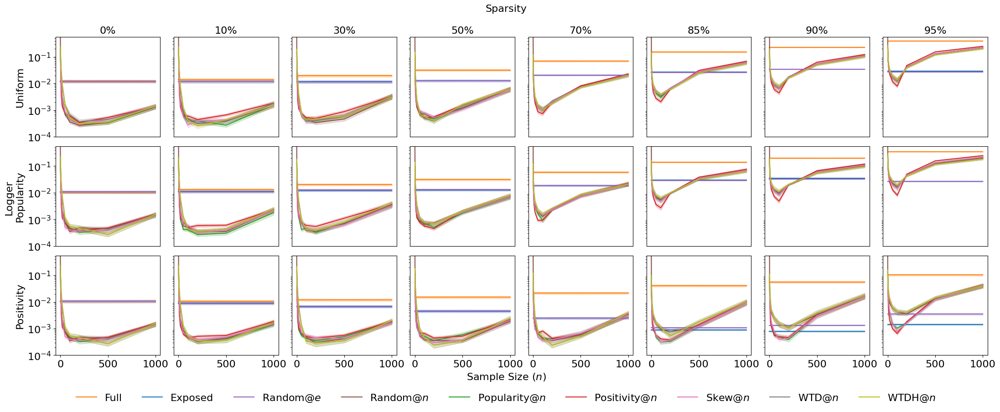

In [19]:
plot_sampler_grid_with_hardness(
    data_by_biastype_metric_bias_samplerblock=
        q1_tierate_by_biastype_metric_biasmodel_samplerblock,
    bias_types=bias_types,
    available_metrics=available_metrics,
    metric_name=METRIC_NAME,
    samplers_blocks=samplers_blocks,
    percentages_to_plot=[0, 10, 30, 50, 70, 85, 90, 95],
    value_col_name="tie_rate",
    yscale="log",
    ylim=(0.0001, 0.55),
    output_path=".",
    filename="q1_resolution_line.pdf"
)

##### Q1.1: Easy combination of models

In [20]:
rankdf_by_biastype_metric_biasmodel_samplerblock_easy = {}
score_cols = ["clickpop_full", "sar-cosine_full", "random_full"]
keep_cols = score_cols + ["biastype", "metric", "bias", "sampler"]

for bias_type, df_by_metric_biasmodel_sampler in df_by_biastype_metric_biasmodel_sampler.items():
    rankdf_by_biastype_metric_biasmodel_samplerblock_easy[bias_type] = {}
    for metric, df_by_biasmodel_sampler in df_by_metric_biasmodel_sampler.items():
        rankdf_by_biastype_metric_biasmodel_samplerblock_easy[bias_type][metric] = {}
        for bias, df_by_sampler in df_by_biasmodel_sampler.items():
            rankdf_by_biastype_metric_biasmodel_samplerblock_easy[bias_type][metric][bias] = {}
            for sampler_key, samplers_order in samplers_blocks.items():
                list_rank_dfs = []
                for sampler in samplers_order:
                    current_df = df_by_sampler[sampler].query("run_id == 0")[keep_cols]

                    # Calculate ranks
                    ranks = current_df[score_cols].rank(
                        axis=1, method="min", numeric_only=True, na_option="keep", ascending=False
                    ).rename(lambda n: "rank_" + n, axis=1)

                    # Concatenate: Original Data (with UserID) + Ranks
                    list_rank_dfs.append(pd.concat([current_df, ranks], axis=1))
                rankdf_by_biastype_metric_biasmodel_samplerblock_easy[bias_type][metric][bias][sampler_key] = pd.concat(list_rank_dfs)

rankdf_by_biastype_metric_biasmodel_samplerblock_easy[bias_type][metric][bias][sampler_key]

#####
q1_tierate_by_biastype_metric_biasmodel_samplerblock_easy = {}

for biastype, rankdf_by_metric_biasmodel_samplerblock in rankdf_by_biastype_metric_biasmodel_samplerblock_easy.items():
    q1_tierate_by_biastype_metric_biasmodel_samplerblock_easy[biastype] = {}

    for metric, rankdf_by_biasmodel_samplerblock in rankdf_by_metric_biasmodel_samplerblock.items():
        q1_tierate_by_biastype_metric_biasmodel_samplerblock_easy[biastype][metric] = {}

        for bias, rankdf_by_samplerblock in rankdf_by_biasmodel_samplerblock.items():
            q1_tierate_by_biastype_metric_biasmodel_samplerblock_easy[biastype][metric][bias] = {}

            for samplerblock, rankdf in rankdf_by_samplerblock.items():
                df_ties = rankdf.copy()

                rank_cols = [c for c in df_ties.columns if "rank_" in c]
                score_cols = [c.replace("rank_", "") for c in rank_cols]

                # Detect the actual count of valid models for each row
                valid_models_count = df_ties[score_cols].notna().sum(axis=1)

                max_rank = int(df_ties[rank_cols].max().max()) if not df_ties[rank_cols].isna().all().all() else 0

                for count_rank in range(1, max_rank + 1):
                    df_ties[count_rank] = (df_ties[rank_cols] == count_rank).sum(axis=1)

                df_ties["ties"] = 0
                df_ties["comps"] = valid_models_count * (valid_models_count - 1) / 2

                for count_rank in range(1, max_rank + 1):
                    df_ties[f"{count_rank}_norm"] = (df_ties[count_rank] * (df_ties[count_rank] - 1.0) / 2.0).abs()
                    df_ties["ties"] += df_ties[f"{count_rank}_norm"]

                # Prevent division by zero
                mask_comps = df_ties["comps"] > 0
                df_ties.loc[mask_comps, "tie_rate"] = df_ties.loc[mask_comps, "ties"] / df_ties.loc[mask_comps, "comps"]
                df_ties.loc[~mask_comps, "tie_rate"] = 0.0

                q1_tierate_by_biastype_metric_biasmodel_samplerblock_easy[biastype][metric][bias][samplerblock] = (
                    df_ties.reset_index().pivot(index=["run_id", "userID"], columns="sampler", values="tie_rate").copy()
                )

q1_tierate_by_biastype_metric_biasmodel_samplerblock_easy[bias_type][METRIC_NAME][bias][samplerblock].head(5)

sampler        CNCFULL  CNCRANDEXPO  EXPOSED   GT    WTDH@1  WTDH@10  \
run_id userID                                                          
0      14          0.0          0.0      0.0  0.0  0.333333      0.0   
       19          0.0          0.0      0.0  0.0  0.333333      0.0   
       21          0.0          0.0      0.0  0.0  0.333333      0.0   
       23          0.0          0.0      0.0  0.0  0.333333      0.0   
       24          0.0          0.0      0.0  0.0  0.333333      0.0   

sampler        WTDH@100  WTDH@1000    WTDH@2  WTDH@20  WTDH@200    WTDH@5  \
run_id userID                                                               
0      14           0.0        0.0  0.000000      0.0       0.0  0.000000   
       19           0.0        0.0  0.333333      0.0       0.0  0.000000   
       21           0.0        0.0  0.333333      0.0       0.0  0.333333   
       23           0.0        0.0  0.333333      0.0       0.0  0.333333   
       24           0.0        0.0  0.000000      0.0       0.0  0.000000   

sampler        WTDH@50  WTDH@500  
run_id userID                     
0      14          0.0       0.0  
       19          0.0       0.0  
       21          0.0       0.0  
       23          0.0       0.0  
       24          0.0       0.0

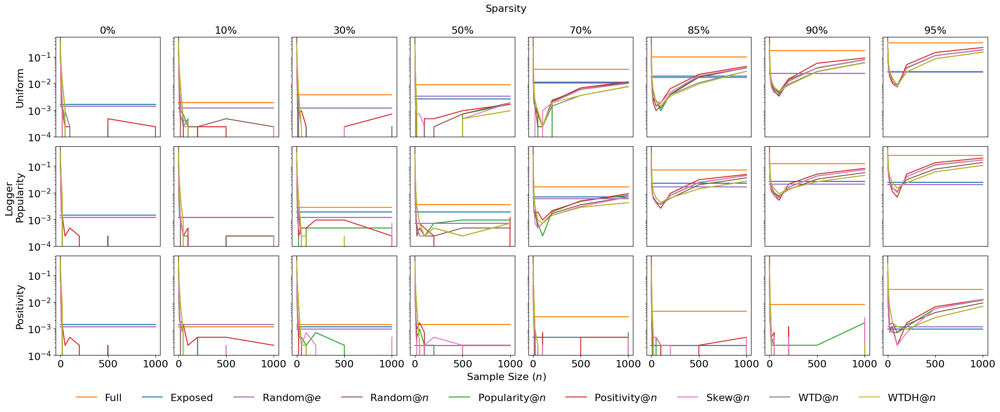

In [21]:
plot_sampler_grid_with_hardness(
    data_by_biastype_metric_bias_samplerblock=
        q1_tierate_by_biastype_metric_biasmodel_samplerblock_easy,
    bias_types=bias_types,
    available_metrics=available_metrics,
    metric_name=METRIC_NAME,
    samplers_blocks=samplers_blocks,
    percentages_to_plot=[0, 10, 30, 50, 70, 85, 90, 95],
    value_col_name="tie_rate",
    yscale="log",
    ylim=(0.0001, 0.55),
    output_path=".",
    filename="q1_resolution_line_easy.pdf"
)

##### Q1.2 Hard combination of models

In [22]:
rankdf_by_biastype_metric_biasmodel_samplerblock_hard = {}
score_cols = ["fastai_full", "clickpop_full", "lightgcn_full", "ease_full", "als_full"]  # Hard combination
keep_cols = score_cols + ["biastype", "metric", "bias", "sampler"]

for bias_type, df_by_metric_biasmodel_sampler in df_by_biastype_metric_biasmodel_sampler.items():
    rankdf_by_biastype_metric_biasmodel_samplerblock_hard[bias_type] = {}
    for metric, df_by_biasmodel_sampler in df_by_metric_biasmodel_sampler.items():
        rankdf_by_biastype_metric_biasmodel_samplerblock_hard[bias_type][metric] = {}
        for bias, df_by_sampler in df_by_biasmodel_sampler.items():
            rankdf_by_biastype_metric_biasmodel_samplerblock_hard[bias_type][metric][bias] = {}
            for sampler_key, samplers_order in samplers_blocks.items():
                list_rank_dfs = []
                for sampler in samplers_order:
                    current_df = df_by_sampler[sampler].query("run_id == 0")[keep_cols]

                    # Calculate ranks
                    ranks = current_df[score_cols].rank(
                        axis=1, method="min", numeric_only=True, na_option="keep", ascending=False
                    ).rename(lambda n: "rank_" + n, axis=1)

                    # Concatenate: Original Data (with UserID) + Ranks
                    list_rank_dfs.append(pd.concat([current_df, ranks], axis=1))
                rankdf_by_biastype_metric_biasmodel_samplerblock_hard[bias_type][metric][bias][sampler_key] = pd.concat(list_rank_dfs)

rankdf_by_biastype_metric_biasmodel_samplerblock_hard[bias_type][metric][bias][sampler_key]

#####
q1_tierate_by_biastype_metric_biasmodel_samplerblock_hard = {}

for biastype, rankdf_by_metric_biasmodel_samplerblock in rankdf_by_biastype_metric_biasmodel_samplerblock_hard.items():
    q1_tierate_by_biastype_metric_biasmodel_samplerblock_hard[biastype] = {}

    for metric, rankdf_by_biasmodel_samplerblock in rankdf_by_metric_biasmodel_samplerblock.items():
        q1_tierate_by_biastype_metric_biasmodel_samplerblock_hard[biastype][metric] = {}

        for bias, rankdf_by_samplerblock in rankdf_by_biasmodel_samplerblock.items():
            q1_tierate_by_biastype_metric_biasmodel_samplerblock_hard[biastype][metric][bias] = {}

            for samplerblock, rankdf in rankdf_by_samplerblock.items():
                df_ties = rankdf.copy()

                rank_cols = [c for c in df_ties.columns if "rank_" in c]
                score_cols = [c.replace("rank_", "") for c in rank_cols]

                # Detect the actual count of valid models for each row
                valid_models_count = df_ties[score_cols].notna().sum(axis=1)

                max_rank = int(df_ties[rank_cols].max().max()) if not df_ties[rank_cols].isna().all().all() else 0

                for count_rank in range(1, max_rank + 1):
                    df_ties[count_rank] = (df_ties[rank_cols] == count_rank).sum(axis=1)

                df_ties["ties"] = 0
                df_ties["comps"] = valid_models_count * (valid_models_count - 1) / 2

                for count_rank in range(1, max_rank + 1):
                    df_ties[f"{count_rank}_norm"] = (df_ties[count_rank] * (df_ties[count_rank] - 1.0) / 2.0).abs()
                    df_ties["ties"] += df_ties[f"{count_rank}_norm"]

                # Prevent division by zero
                mask_comps = df_ties["comps"] > 0
                df_ties.loc[mask_comps, "tie_rate"] = df_ties.loc[mask_comps, "ties"] / df_ties.loc[mask_comps, "comps"]
                df_ties.loc[~mask_comps, "tie_rate"] = 0.0

                q1_tierate_by_biastype_metric_biasmodel_samplerblock_hard[biastype][metric][bias][samplerblock] = (
                    df_ties.reset_index().pivot(index=["run_id", "userID"], columns="sampler", values="tie_rate").copy()
                )

q1_tierate_by_biastype_metric_biasmodel_samplerblock_hard[bias_type][METRIC_NAME][bias][samplerblock].head(5)

sampler        CNCFULL  CNCRANDEXPO  EXPOSED   GT  WTDH@1  WTDH@10  WTDH@100  \
run_id userID                                                                  
0      14          0.0          0.0      0.0  0.0     0.1      0.0       0.0   
       19          0.0          0.0      0.0  0.0     0.2      0.1       0.0   
       21          0.0          0.0      0.0  0.0     0.1      0.0       0.0   
       23          0.0          0.0      0.0  0.0     0.0      0.0       0.0   
       24          0.0          0.0      0.0  0.0     0.1      0.0       0.0   

sampler        WTDH@1000  WTDH@2  WTDH@20  WTDH@200  WTDH@5  WTDH@50  WTDH@500  
run_id userID                                                                   
0      14            0.0     0.0      0.0       0.0     0.0      0.0       0.0  
       19            0.0     0.2      0.0       0.0     0.2      0.0       0.0  
       21            0.0     0.1      0.0       0.0     0.1      0.0       0.0  
       23            0.0     0.0      0.0       0.0     0.0      0.0       0.0  
       24            0.0     0.0      0.0       0.0     0.0      0.0       0.0

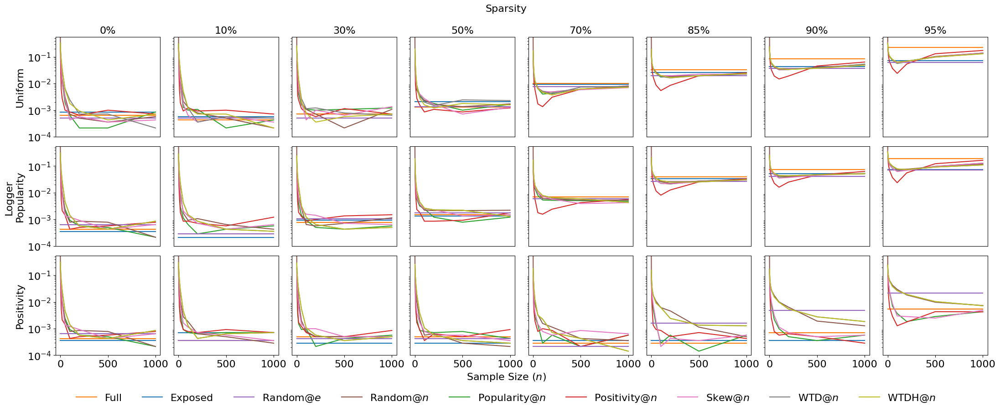

In [23]:
plot_sampler_grid_with_hardness(
    data_by_biastype_metric_bias_samplerblock=
        q1_tierate_by_biastype_metric_biasmodel_samplerblock_hard,
    bias_types=bias_types,
    available_metrics=available_metrics,
    metric_name=METRIC_NAME,
    samplers_blocks=samplers_blocks,
    percentages_to_plot=[0, 10, 30, 50, 70, 85, 90, 95],
    value_col_name="tie_rate",
    yscale="log",
    ylim=(0.0001, 0.55),
    output_path=".",
    filename="q1_resolution_line_hard.pdf"
)

### Position-Based Kendall Correlation ($L$)

In [17]:
# https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.corrwith.html
# {‘pearson’, ‘kendall’, ‘spearman’}
import os
from concurrent.futures import as_completed, ProcessPoolExecutor

q2_kendalldf_by_biastype_metric_biasmodel_samplerblock = {}

def compute_kendalltau(df1, df2, colname, key):
    return key, pd.DataFrame(df1.corrwith(df2, method="kendall", axis=1), columns=[colname])

with ProcessPoolExecutor(max_workers=int(os.cpu_count() * 0.9)) as executor:
    for bias_type, df_by_metric_biasmodel_sampler in df_by_biastype_metric_biasmodel_sampler.items():
        q2_kendalldf_by_biastype_metric_biasmodel_samplerblock[bias_type] = {}
        for metric, df_by_biasmodel_sampler in df_by_metric_biasmodel_sampler.items():
            if metric != METRIC_NAME:
                continue

            q2_kendalldf_by_biastype_metric_biasmodel_samplerblock[bias_type][metric] = {}
            for bias, df_by_sampler in df_by_biasmodel_sampler.items():
                q2_kendalldf_by_biastype_metric_biasmodel_samplerblock[bias_type][metric][bias] = {}
                future_to_sampler = []
                for sampler_key, samplers_order in samplers_blocks.items():
                    for sampler1 in samplers_order:

                        rankdf_sampler1 = df_by_sampler[sampler1][recs].rank(
                            axis=1, method="min", numeric_only=True, na_option="keep", ascending=False
                        )

                        if rankdf_sampler1.shape[0] == 0:
                            continue

                        rankdf_gt = df_by_sampler["CNCFULL"][recs].rank(
                            axis=1, method="min", numeric_only=True, na_option="keep", ascending=False
                        )

                        future_to_sampler.append(
                            executor.submit(
                                compute_kendalltau, rankdf_sampler1, rankdf_gt, sampler1, sampler_key
                            )
                        )

                corrdf_by_samplerkey = {}
                for future in as_completed(future_to_sampler):
                    sampler_key, corr_df = future.result()
                    corrdf_by_samplerkey.setdefault(sampler_key, [])
                    corrdf_by_samplerkey[sampler_key].append(corr_df)

                for sampler_key, list_corr in corrdf_by_samplerkey.items():
                    q2_kendalldf_by_biastype_metric_biasmodel_samplerblock[bias_type][metric][bias][sampler_key] = pd.concat(list_corr, axis=1)

q2_kendalldf_by_biastype_metric_biasmodel_samplerblock[bias_type][METRIC_NAME][bias][sampler_key].head(5)

WTDH@100  CNCFULL    WTDH@2   WTDH@20  WTDH@500    WTDH@1  \
run_id userID                                                              
0      14      0.625305      1.0  0.267791  0.531510  0.719101  0.200111   
       19      0.822440      1.0  0.504520  0.756644  0.855337  0.290957   
       21      0.839719      1.0  0.496397  0.687043  0.870254  0.472310   
       23      0.666667      1.0  0.511766  0.727273  0.696970  0.517207   
       24      0.762770      1.0  0.592474  0.826334  0.826334  0.436990   

                WTDH@10    WTDH@5   WTDH@50   EXPOSED  CNCRANDEXPO  WTDH@1000  \
run_id userID                                                                   
0      14      0.406449  0.406449  0.719101  0.468979     0.719101   0.850631   
       19      0.679568  0.734968  0.789542  0.756644     0.723747   0.897085   
       21      0.625972  0.656525  0.839719  0.503831     0.900790   0.809184   
       23      0.606061  0.604815  0.757576  0.575758     0.636364   0.515152   
       24      0.699206  0.572078  0.794552  0.858116     0.889898   0.864692   

               WTDH@200        GT  
run_id userID                      
0      14      0.750366  0.625305  
       19      0.789542  0.729293  
       21      0.748113  0.870254  
       23      0.727273  0.545455  
       24      0.762770  0.635642

#### Q2: Fidelity

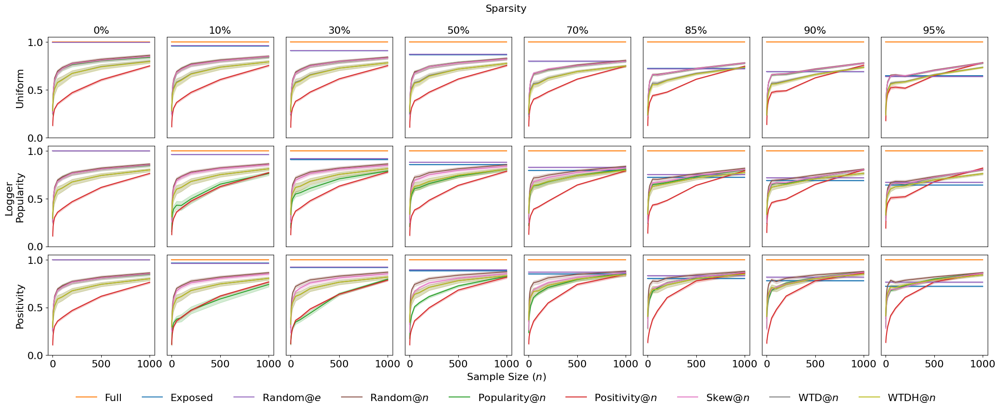

In [18]:
plot_sampler_grid_with_hardness(
    q2_kendalldf_by_biastype_metric_biasmodel_samplerblock,
    bias_types=bias_types,
    available_metrics=available_metrics,
    metric_name=METRIC_NAME,
    samplers_blocks=samplers_blocks,
    percentages_to_plot=[0, 10, 30, 50, 70, 85, 90, 95],
    value_col_name="kendall",
    yscale=None,
    ylim=(0, 1.05),
    output_path=".",
    filename="q2_fidelity_g_gs_l_ls_line.pdf"
)

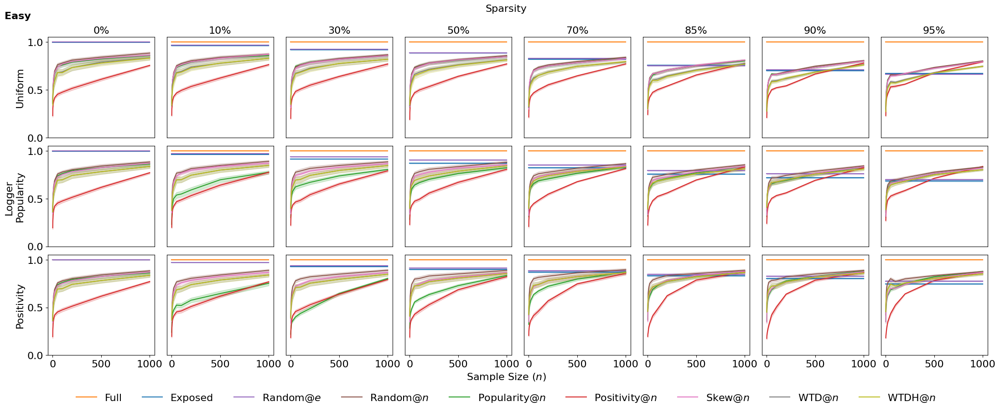

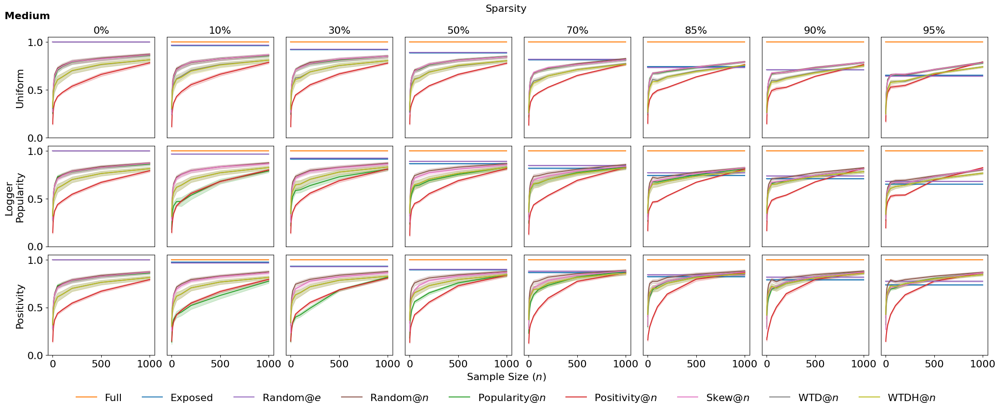

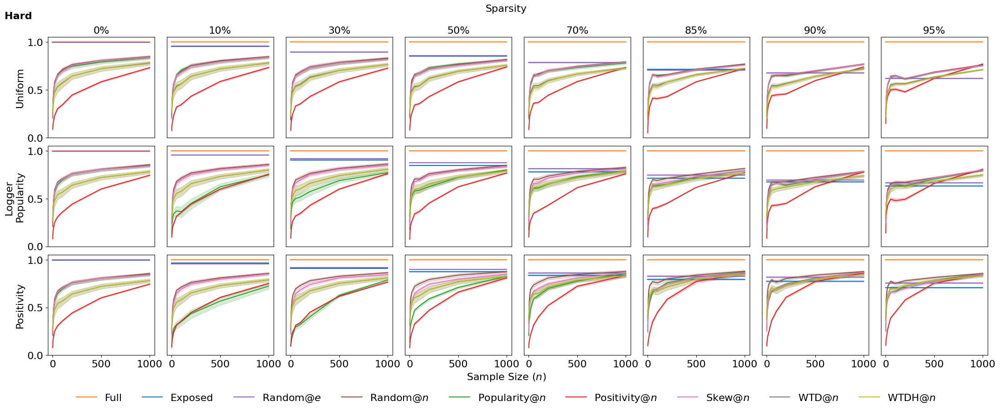

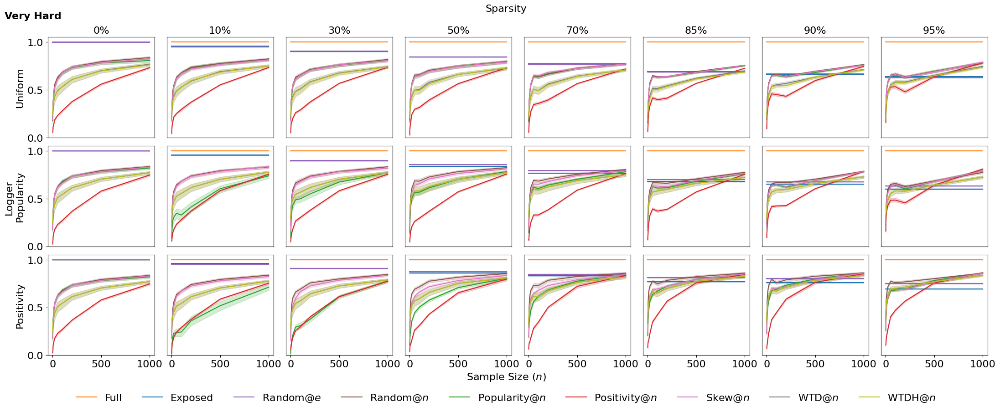

In [19]:
plot_sampler_grid_with_hardness(
    data_by_biastype_metric_bias_samplerblock=q2_kendalldf_by_biastype_metric_biasmodel_samplerblock,
    bias_types=bias_types,
    available_metrics=available_metrics,
    metric_name=METRIC_NAME,
    samplers_blocks=samplers_blocks,
    percentages_to_plot=[0, 10, 30, 50, 70, 85, 90, 95],
    value_col_name="kendall",
    yscale=None,
    ylim=(0, 1.05),
    user_hardness=user_hardness,
    output_path=".",
    filename="q2_fidelity_g_gs_l_ls_line.pdf"
)

### Position-Based Kendall Correlation ($G_S$)
$L_S == G$ when used Full at 100% density vs $G_S$

In [20]:
# https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.corrwith.html
# {‘pearson’, ‘kendall’, ‘spearman’}
import os
from concurrent.futures import as_completed, ProcessPoolExecutor

q3_kendalldf_by_biastype_metric_biasmodel_samplerblock = {}

def compute_kendalltau(df1, df2, colname, key):
    return key, pd.DataFrame(df1.corrwith(df2, method="kendall", axis=1), columns=[colname])

with ProcessPoolExecutor(max_workers=int(os.cpu_count() * 0.9)) as executor:
    for bias_type, df_by_metric_biasmodel_sampler in df_by_biastype_metric_biasmodel_sampler.items():
        q3_kendalldf_by_biastype_metric_biasmodel_samplerblock[bias_type] = {}
        for metric, df_by_biasmodel_sampler in df_by_metric_biasmodel_sampler.items():
            if metric != METRIC_NAME:
                continue

            q3_kendalldf_by_biastype_metric_biasmodel_samplerblock[bias_type][metric] = {}
            for bias, df_by_sampler in df_by_biasmodel_sampler.items():
                q3_kendalldf_by_biastype_metric_biasmodel_samplerblock[bias_type][metric][bias] = {}
                future_to_sampler = []
                for sampler_key, samplers_order in samplers_blocks.items():
                    for sampler1 in samplers_order:

                        rankdf_sampler1 = df_by_sampler[sampler1][recs].rank(
                            axis=1, method="min", numeric_only=True, na_option="keep", ascending=False
                        )

                        if rankdf_sampler1.shape[0] == 0:
                            continue

                        rankdf_gt = df_by_biasmodel_sampler["".join([b for b in bias if not b.isdigit()]) + "0"][sampler1][recs].rank(
                            axis=1, method="min", numeric_only=True, na_option="keep", ascending=False
                        )

                        future_to_sampler.append(
                            executor.submit(
                                compute_kendalltau, rankdf_sampler1, rankdf_gt, sampler1, sampler_key
                            )
                        )

                corrdf_by_samplerkey = {}
                for future in as_completed(future_to_sampler):
                    sampler_key, corr_df = future.result()
                    corrdf_by_samplerkey.setdefault(sampler_key, [])
                    corrdf_by_samplerkey[sampler_key].append(corr_df)

                for sampler_key, list_corr in corrdf_by_samplerkey.items():
                    q3_kendalldf_by_biastype_metric_biasmodel_samplerblock[bias_type][metric][bias][sampler_key] = pd.concat(list_corr, axis=1)

q3_kendalldf_by_biastype_metric_biasmodel_samplerblock[bias_type][METRIC_NAME][bias][sampler_key].head(5)

WTDH@2    WTDH@1  WTDH@100   GT  WTDH@500   CNCFULL  \
run_id userID                                                          
0      14      0.672538  0.782960  0.696970  1.0  0.696970  0.625305   
       19      0.895049  0.938973  0.575758  1.0  0.757576  0.729293   
       21      0.857173  0.854732  0.787879  1.0  0.818182  0.870254   
       23      0.184017  0.167812  0.636364  1.0  0.606061  0.545455   
       24      0.482906  0.522921  0.727273  1.0  0.666667  0.635642   

                WTDH@50    WTDH@5   WTDH@10   WTDH@20  WTDH@1000  WTDH@200  \
run_id userID                                                                
0      14      0.545455  0.656508  0.564902  0.696970   0.625972  0.545455   
       19      0.757576  0.800095  0.870254  0.787879   0.730988  0.787879   
       21      0.727273  0.839146  0.757576  0.757576   0.848485  0.878788   
       23      0.656508  0.570157  0.198479  0.748113   0.666667  0.727273   
       24      0.454545  0.394771  0.333333  0.454545   0.748113  0.696970   

                EXPOSED  CNCRANDEXPO  
run_id userID                         
0      14      0.424242     0.545455  
       19      0.839719     0.748113  
       21      0.454545     0.787879  
       23      0.484848     0.545455  
       24      0.606061     0.515152

#### Q3: Robustness

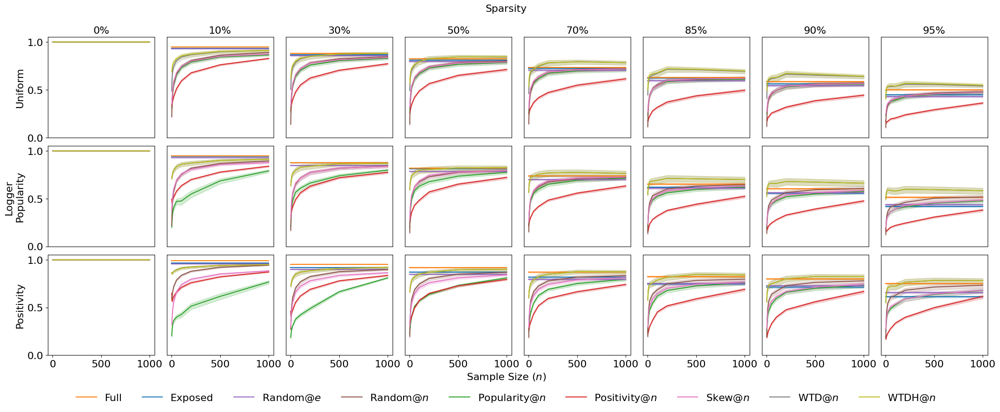

In [21]:
plot_sampler_grid_with_hardness(
    q3_kendalldf_by_biastype_metric_biasmodel_samplerblock,
    bias_types=bias_types,
    available_metrics=available_metrics,
    metric_name=METRIC_NAME,
    samplers_blocks=samplers_blocks,
    percentages_to_plot=[0, 10, 30, 50, 70, 85, 90, 95],
    value_col_name="kendall",
    yscale=None,
    ylim=(0, 1.05),
    output_path=".",
    filename="q3_robustness_line.pdf"
)

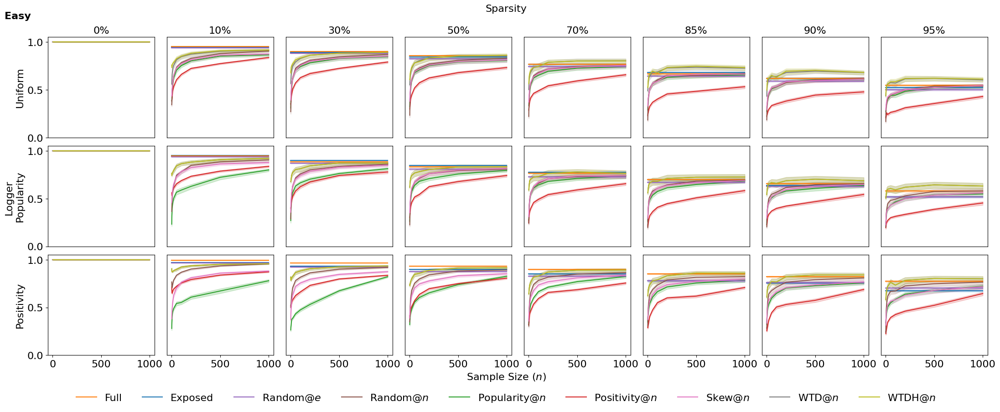

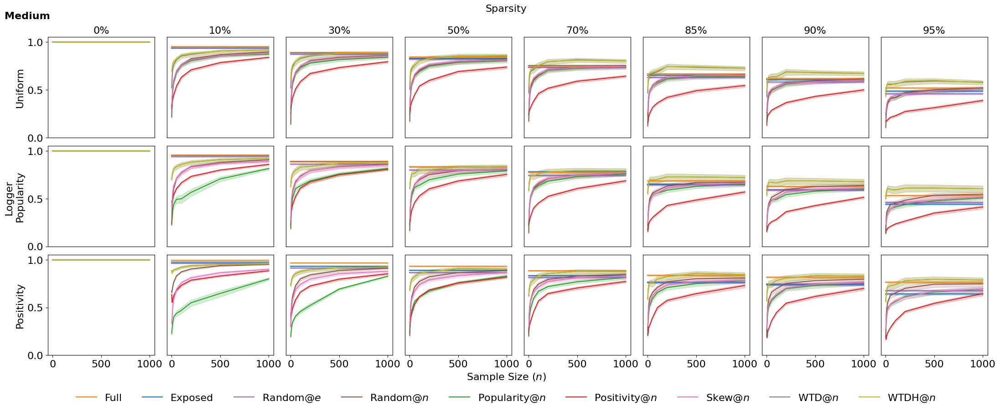

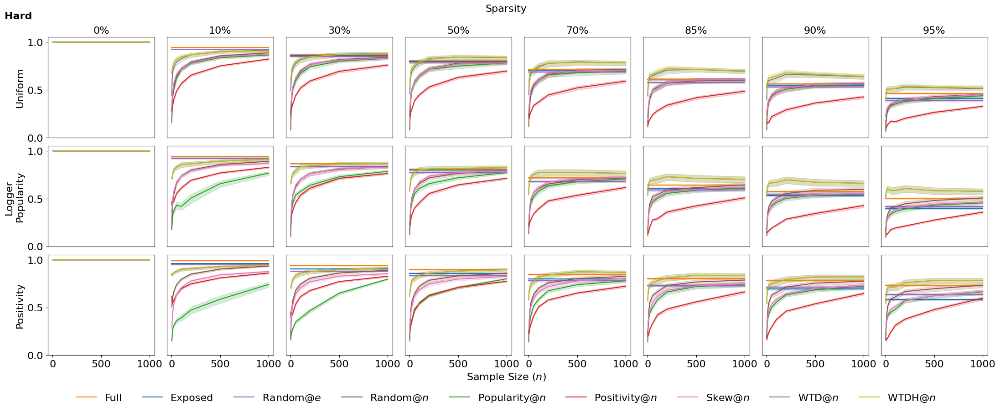

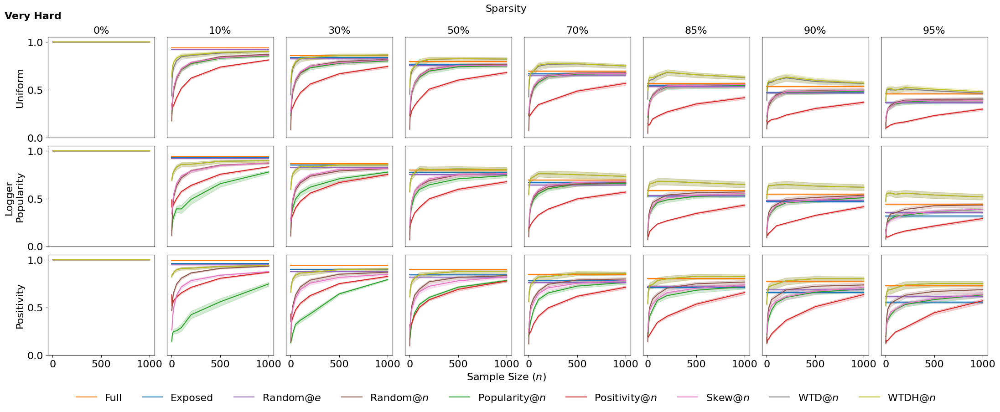

In [22]:
plot_sampler_grid_with_hardness(
    data_by_biastype_metric_bias_samplerblock=q3_kendalldf_by_biastype_metric_biasmodel_samplerblock,
    bias_types=bias_types,
    available_metrics=available_metrics,
    metric_name=METRIC_NAME,
    samplers_blocks=samplers_blocks,
    percentages_to_plot=[0, 10, 30, 50, 70, 85, 90, 95],
    value_col_name="kendall",
    yscale=None,
    ylim=(0, 1.05),
    user_hardness=user_hardness,
    output_path=".",
    filename="q3_robustness_line.pdf"
)

### Position-Based Kendall Correlation ($G$)

In [23]:
# https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.corrwith.html
# {‘pearson’, ‘kendall’, ‘spearman’}
import os
from concurrent.futures import as_completed, ProcessPoolExecutor

q4_kendalldf_by_biastype_metric_biasmodel_samplerblock = {}

def compute_kendalltau(df1, df2, colname, key):
    return key, pd.DataFrame(df1.corrwith(df2, method="kendall", axis=1), columns=[colname])

with ProcessPoolExecutor(max_workers=int(os.cpu_count() * 0.9)) as executor:
    for bias_type, df_by_metric_biasmodel_sampler in df_by_biastype_metric_biasmodel_sampler.items():
        q4_kendalldf_by_biastype_metric_biasmodel_samplerblock[bias_type] = {}
        for metric, df_by_biasmodel_sampler in df_by_metric_biasmodel_sampler.items():
            if metric != METRIC_NAME:
                continue

            q4_kendalldf_by_biastype_metric_biasmodel_samplerblock[bias_type][metric] = {}
            for bias, df_by_sampler in df_by_biasmodel_sampler.items():
                q4_kendalldf_by_biastype_metric_biasmodel_samplerblock[bias_type][metric][bias] = {}
                future_to_sampler = []
                for sampler_key, samplers_order in samplers_blocks.items():
                    for sampler1 in samplers_order:

                        rankdf_sampler1 = df_by_sampler[sampler1][recs].rank(
                            axis=1, method="min", numeric_only=True, na_option="keep", ascending=False
                        )

                        if rankdf_sampler1.shape[0] == 0:
                            continue

                        rankdf_gt = df_by_sampler["GT"][recs].rank(
                            axis=1, method="min", numeric_only=True, na_option="keep", ascending=False
                        )

                        future_to_sampler.append(
                            executor.submit(
                                compute_kendalltau, rankdf_sampler1, rankdf_gt, sampler1, sampler_key
                            )
                        )

                corrdf_by_samplerkey = {}
                for future in as_completed(future_to_sampler):
                    sampler_key, corr_df = future.result()
                    corrdf_by_samplerkey.setdefault(sampler_key, [])
                    corrdf_by_samplerkey[sampler_key].append(corr_df)

                for sampler_key, list_corr in corrdf_by_samplerkey.items():
                    q4_kendalldf_by_biastype_metric_biasmodel_samplerblock[bias_type][metric][bias][sampler_key] = pd.concat(list_corr, axis=1)

q4_kendalldf_by_biastype_metric_biasmodel_samplerblock[bias_type][METRIC_NAME][bias][sampler_key].head(5)

WTDH@1    WTDH@2  WTDH@1000   CNCFULL   WTDH@10   GT  \
run_id userID                                                           
0      14      0.096976  0.198479   0.625972  0.625305  0.272727  1.0   
       19      0.219427  0.516734   0.720577  0.729293  0.646154  1.0   
       21      0.452556  0.413167   0.757576  0.870254  0.575758  1.0   
       23      0.387905  0.294653   0.545455  0.545455  0.333333  1.0   
       24      0.272428  0.412226   0.625972  0.635642  0.575758  1.0   

                 WTDH@5  WTDH@200  WTDH@500   WTDH@20   EXPOSED   WTDH@50  \
run_id userID                                                               
0      14      0.393939  0.545455  0.484848  0.393939  0.424242  0.484848   
       19      0.697695  0.687043  0.656508  0.687043  0.839719  0.687043   
       21      0.572078  0.696970  0.818182  0.575758  0.454545  0.848485   
       23      0.387702  0.636364  0.545455  0.515152  0.484848  0.545455   
       24      0.363636  0.606061  0.636364  0.636364  0.606061  0.545455   

               WTDH@100  CNCRANDEXPO  
run_id userID                         
0      14      0.484848     0.545455  
       19      0.656508     0.748113  
       21      0.787879     0.787879  
       23      0.575758     0.545455  
       24      0.606061     0.515152

#### Q4: Predictive Power

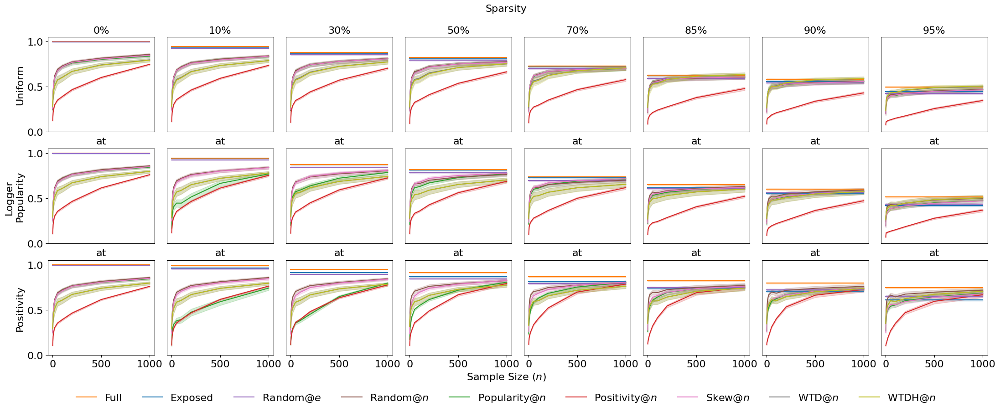

In [24]:
plot_sampler_grid(
    data_by_biastype_metric_bias_samplerblock=q4_kendalldf_by_biastype_metric_biasmodel_samplerblock,
    bias_types=bias_types,
    available_metrics=available_metrics,
    metric_name=METRIC_NAME,
    samplers_blocks=samplers_blocks,
    percentages_to_plot=[0, 10, 30, 50, 70, 85, 90, 95],
    value_col_name="kendall",
    yscale=None,
    ylim=(0, 1.05),
    output_path=".",
    filename="q4_predictive_power_line.pdf"
)

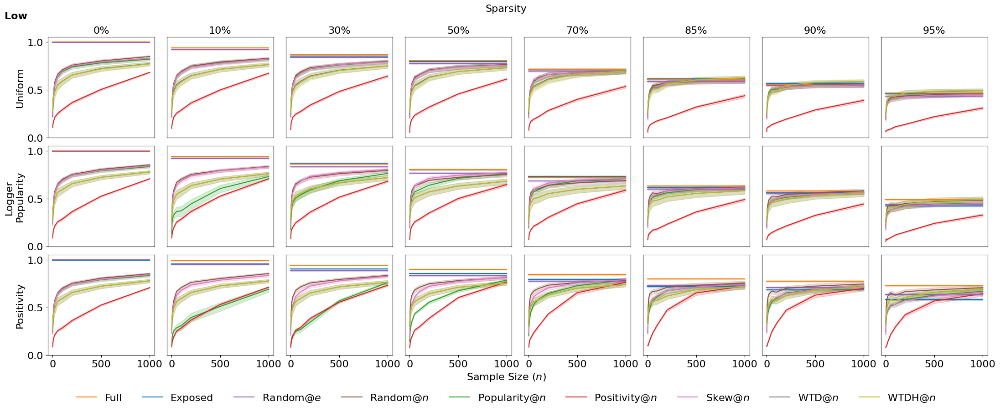

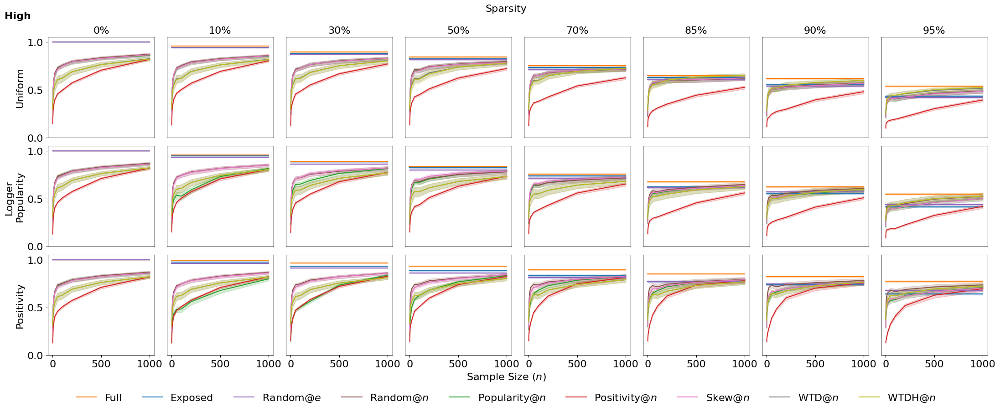

In [25]:
plot_sampler_grid_with_hardness(
    data_by_biastype_metric_bias_samplerblock=q4_kendalldf_by_biastype_metric_biasmodel_samplerblock,
    bias_types=bias_types,
    available_metrics=available_metrics,
    metric_name=METRIC_NAME,
    samplers_blocks=samplers_blocks,
    percentages_to_plot=[0, 10, 30, 50, 70, 85, 90, 95],
    value_col_name="kendall",
    yscale=None,
    ylim=(0, 1.05),
    user_hardness=user_history,
    output_path=".",
    filename="q4_predictive_power_line_history.pdf"
)

## Meta Evaluation Correlation

### Support Functions

In [26]:
def build_q1_q4_dataframe(q1_dict, q2_dict, q3_dict, q4_dict, *, bias_types, metric_name, sampler_block, sampler_name):
    """
    Build a unified DataFrame containing Q1–Q4 values joined by userID.

    All dictionaries are assumed to have the same structure:
        [biastype][metric][bias][sampler_block] -> DataFrame
            index   = userID
            columns = samplers

    The sampler dimension is reduced by selecting `sampler_name`.
    """

    records = []

    for biastype in bias_types:
        for bias in q1_dict[biastype][metric_name]:

            # Extract per-question series for the selected sampler
            q1 = (
                q1_dict[biastype][metric_name][bias][sampler_block]
                .loc[:, sampler_name]
                .rename("Q1")
                .loc[0]
            )
            q2 = (
                q2_dict[biastype][metric_name][bias][sampler_block]
                .loc[:, sampler_name]
                .rename("Q2")
                .loc[0]
            )
            q3 = (
                q3_dict[biastype][metric_name][bias][sampler_block]
                .loc[:, sampler_name]
                .rename("Q3")
                .loc[0]
            )
            q4 = (
                q4_dict[biastype][metric_name][bias][sampler_block]
                .loc[:, sampler_name]
                .rename("Q4")
                .loc[0]
            )

            # Join by userID (index)
            df = (
                q1.to_frame()
                .join(q2, how="inner")
                .join(q3, how="inner")
                .join(q4, how="inner")
            )

            df["biastype"] = biastype
            df["bias"] = bias

            records.append(df.reset_index())

    return pd.concat(records, ignore_index=True)

In [27]:
def plot_q_correlation_heatmap(df_q, *, title, method="spearman", vmin=-1, vmax=1):
    corr = df_q[["Q1", "Q2", "Q3", "Q4"]].corr(method=method)
    triag_mask = np.triu(corr)
    plt.figure(figsize=(6, 5))
    sns.heatmap(
        corr,
        annot=True,
        cmap="coolwarm",
        vmin=vmin,
        vmax=vmax,
        square=True,
        mask=triag_mask
    )
    plt.title(title, fontsize=16)
    plt.tight_layout()
    plt.show()


def plot_q_correlation_grid(
    df_q,
    *,
    bias_types,
    percentages_to_plot,
    sampler_name,
    method="spearman",
    figsize=(22, 8),
    vmin=-1,
    vmax=1,
    user_hardness=None,
    output_path=None,
    filename=None
):
    """
    Plot a compact grid of Q1–Q4 correlation heatmaps.

    Layout:
        rows    -> biastype (logger)
        columns -> sparsity percentage

    Axis labels:
        - Y labels only on first column
        - X labels only on last row

    A single colorbar is placed outside the grid.
    """

    # --------------------------------------------------
    # Decide how many figures we will plot
    # --------------------------------------------------
    if user_hardness is None:
        category_iter = [(None, None)]
    else:
        category_iter = [
            (cat, user_hardness[user_hardness["difficulty_group"] == cat])
            for cat in user_hardness["difficulty_group"].cat.categories
        ]

    for category_name, hardness_df in category_iter:

        fig, axes = plt.subplots(
            nrows=len(bias_types),
            ncols=len(percentages_to_plot),
            figsize=figsize,
            constrained_layout=False
        )

        # Create a dedicated axis for the colorbar
        cbar_ax = fig.add_axes([0.92, 0.15, 0.015, 0.7])

        for i, biastype in enumerate(bias_types):
            for j, p in enumerate(percentages_to_plot):
                ax = axes[i][j]

                bias_label = f"{biastype}{p}"
                subdf = df_q.query(
                    "biastype == @biastype and bias == @bias_label"
                ).copy()

                if subdf.empty:
                    ax.axis("off")
                    continue

                if hardness_df is not None:
                    if "userID" in subdf.columns:
                        subdf = subdf[subdf["userID"].isin(hardness_df.index)]
                    else:
                        subdf = subdf[subdf.index.get_level_values("userID").isin(hardness_df.index)]

                if "run_id" in subdf.columns:
                    corrs = [
                        subdf[subdf["run_id"] == run_id][["Q1", "Q2", "Q3", "Q4"]].corr(method=method)
                        for run_id in subdf["run_id"].unique()
                    ]
                    corr = sum(corrs) / len(corrs)
                elif "run_id" in subdf.index.names:
                    corrs = [
                        subdf.xs(run_id, level="run_id")[["Q1", "Q2", "Q3", "Q4"]].corr(method=method)
                        for run_id in subdf.index.get_level_values("run_id").unique()
                    ]
                    corr = sum(corrs) / len(corrs)
                else:
                    corr = subdf[["Q1", "Q2", "Q3", "Q4"]].corr(method=method)

                triag_mask = np.triu(corr)

                sns.heatmap(
                    corr,
                    ax=ax,
                    cmap="coolwarm",
                    vmin=vmin,
                    vmax=vmax,
                    square=True,
                    cbar=(i == 0 and j == 0),
                    cbar_ax=cbar_ax if (i == 0 and j == 0) else None,
                    annot=True,
                    fmt='.2f',
                    annot_kws={'fontsize': 12},
                    mask=triag_mask
                )

                # Column titles (sparsity)
                if i == 0:
                    ax.set_title(f"{p}%", fontsize=16)

                # Y-axis labels only on first column
                if j == 0:
                    grid_label = "".join(c for c in biastype if not c.isdigit()).capitalize()
                    if grid_label == "Marpos":
                        grid_label = "Positivity"
                    if grid_label == "Marpop":
                        grid_label = "Popularity"
                    if grid_label == "Random":
                        grid_label = "Uniform"
                    ax.set_ylabel(grid_label, fontsize=16)
                else:
                    ax.set_ylabel("")
                    ax.set_yticklabels([])
                    ax.tick_params(axis='y', length=0)

                # X-axis labels only on last row
                if i == len(bias_types) - 1:
                    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, fontsize=16)
                else:
                    ax.set_xlabel("")
                    ax.set_xticklabels([])
                    ax.tick_params(axis='x', length=0)

        # Global labels
        if category_name is not None:
            fig.text(0.06, 0.95, category_name, va="top", ha="left", weight='bold', fontsize=16)
        fig.text(0.5, 0.95, "Sparsity", ha="center", fontsize=16)
        fig.text(0.06, 0.5, "Logger", va="center", rotation="vertical", fontsize=16)

        fig.subplots_adjust(top=0.90, bottom=0.10, left=0.10, right=0.90, hspace=0.1, wspace=0.1)

        if output_path is not None and filename is not None:
            filename_final = filename
            if category_name is not None:
                filename_final = f"{category_name}_{filename_final}"
            fig.savefig(
                os.path.join(output_path, filename_final),
                dpi=1300,
                bbox_inches="tight",
                pad_inches=0.05
            )

        fig.show()

### General

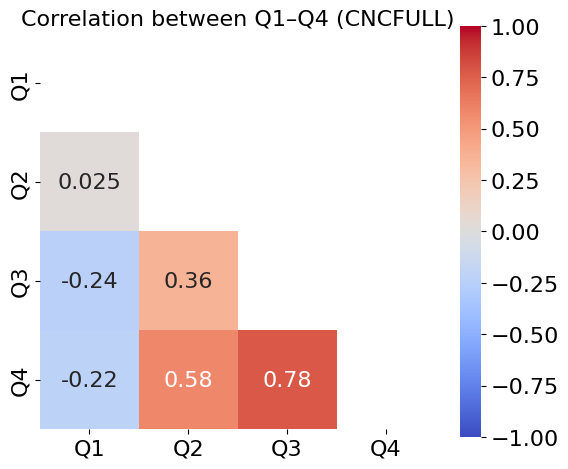

In [ ]:
df_q = build_q1_q4_dataframe(
    q1_dict=q1_tierate_by_biastype_metric_biasmodel_samplerblock,
    q2_dict=q2_kendalldf_by_biastype_metric_biasmodel_samplerblock,
    q3_dict=q3_kendalldf_by_biastype_metric_biasmodel_samplerblock,
    q4_dict=q4_kendalldf_by_biastype_metric_biasmodel_samplerblock,
    bias_types=bias_types,
    metric_name=METRIC_NAME,
    sampler_block="CNCRANDOM",
    sampler_name="CNCRANDOM@1000"
)

plot_q_correlation_heatmap(df_q, title="Correlation between Q1–Q4 (CNCFULL)", method="spearman")

### Q5: Correlation Across Meta-Evaluation

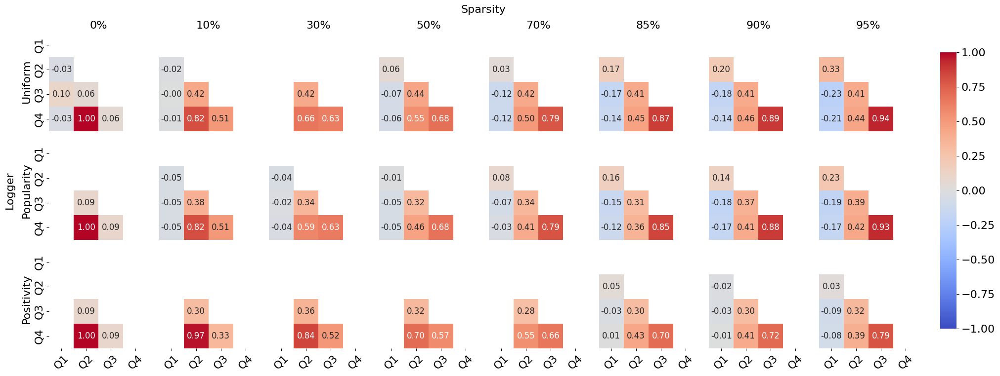

In [ ]:
# Build joint Q1–Q4 dataframe
df_q = build_q1_q4_dataframe(
    q1_dict=q1_tierate_by_biastype_metric_biasmodel_samplerblock,
    q2_dict=q2_kendalldf_by_biastype_metric_biasmodel_samplerblock,
    q3_dict=q3_kendalldf_by_biastype_metric_biasmodel_samplerblock,
    q4_dict=q4_kendalldf_by_biastype_metric_biasmodel_samplerblock,
    bias_types=bias_types,
    metric_name=METRIC_NAME,
    sampler_block="CNCRANDOM",
    sampler_name="CNCRANDOM@1000"
)

plot_q_correlation_grid(
    df_q,
    bias_types=bias_types,
    percentages_to_plot=[0, 10, 30, 50, 70, 85, 90, 95],
    sampler_name="CNCRANDOM@1000",
    method="spearman",
    output_path=".",
    filename="q5_correlation_grid_random1000.pdf"
)

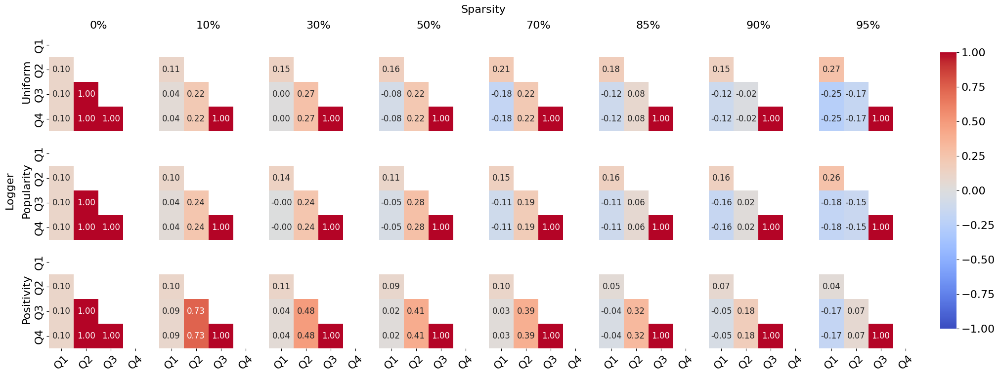

In [ ]:
# Build joint Q1–Q4 dataframe
df_q = build_q1_q4_dataframe(
    q1_dict=q1_tierate_by_biastype_metric_biasmodel_samplerblock,
    q2_dict=q2_kendalldf_by_biastype_metric_biasmodel_samplerblock,
    q3_dict=q3_kendalldf_by_biastype_metric_biasmodel_samplerblock,
    q4_dict=q4_kendalldf_by_biastype_metric_biasmodel_samplerblock,
    bias_types=bias_types,
    metric_name=METRIC_NAME,
    sampler_block="CNCRANDOM",
    sampler_name="CNCFULL"
)

plot_q_correlation_grid(
    df_q,
    bias_types=bias_types,
    percentages_to_plot=[0, 10, 30, 50, 70, 85, 90, 95],
    sampler_name="CNCFULL",
    method="spearman",
    output_path=".",
    filename="q5_correlation_grid_full.pdf"
)

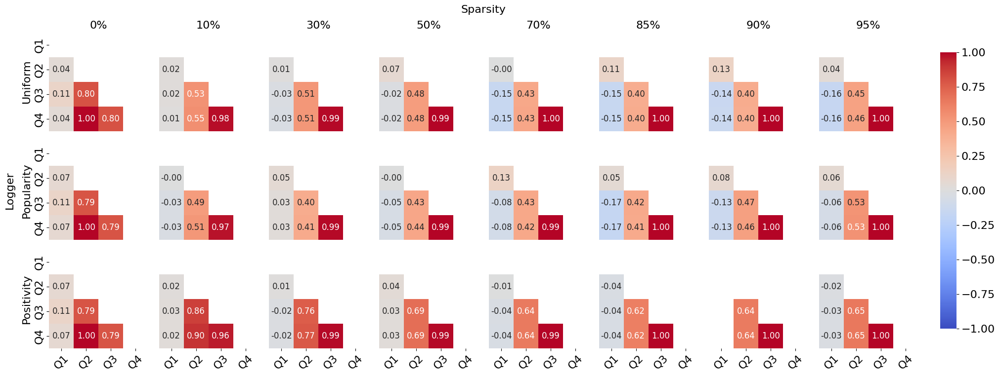

In [ ]:
# Build joint Q1–Q4 dataframe
df_q = build_q1_q4_dataframe(
    q1_dict=q1_tierate_by_biastype_metric_biasmodel_samplerblock,
    q2_dict=q2_kendalldf_by_biastype_metric_biasmodel_samplerblock,
    q3_dict=q3_kendalldf_by_biastype_metric_biasmodel_samplerblock,
    q4_dict=q4_kendalldf_by_biastype_metric_biasmodel_samplerblock,
    bias_types=bias_types,
    metric_name=METRIC_NAME,
    sampler_block="CNCRANDOM",
    sampler_name="EXPOSED"
)

plot_q_correlation_grid(
    df_q,
    bias_types=bias_types,
    percentages_to_plot=[0, 10, 30, 50, 70, 85, 90, 95],
    sampler_name="EXPOSED",
    method="spearman",
    output_path=".",
    filename="q5_correlation_grid_exposed.pdf"
)

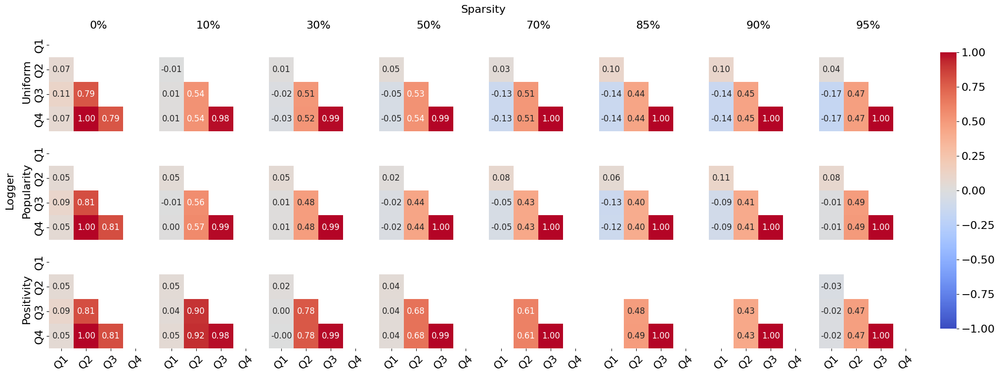

In [ ]:
# Build joint Q1–Q4 dataframe
df_q = build_q1_q4_dataframe(
    q1_dict=q1_tierate_by_biastype_metric_biasmodel_samplerblock,
    q2_dict=q2_kendalldf_by_biastype_metric_biasmodel_samplerblock,
    q3_dict=q3_kendalldf_by_biastype_metric_biasmodel_samplerblock,
    q4_dict=q4_kendalldf_by_biastype_metric_biasmodel_samplerblock,
    bias_types=bias_types,
    metric_name=METRIC_NAME,
    sampler_block="CNCRANDOM",
    sampler_name="CNCRANDEXPO"
)

plot_q_correlation_grid(
    df_q,
    bias_types=bias_types,
    percentages_to_plot=[0, 10, 30, 50, 70, 85, 90, 95],
    sampler_name="CNCRANDEXPO",
    method="spearman",
    output_path=".",
    filename="q5_correlation_grid_randexpo.pdf"
)

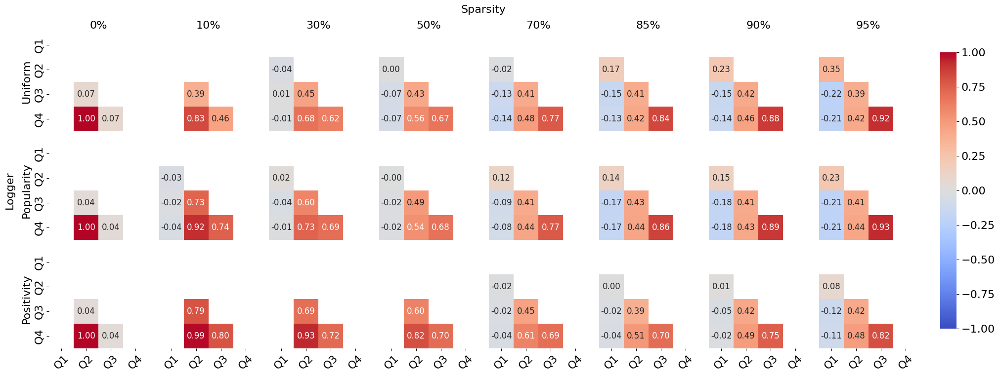

In [ ]:
# Build joint Q1–Q4 dataframe
df_q = build_q1_q4_dataframe(
    q1_dict=q1_tierate_by_biastype_metric_biasmodel_samplerblock,
    q2_dict=q2_kendalldf_by_biastype_metric_biasmodel_samplerblock,
    q3_dict=q3_kendalldf_by_biastype_metric_biasmodel_samplerblock,
    q4_dict=q4_kendalldf_by_biastype_metric_biasmodel_samplerblock,
    bias_types=bias_types,
    metric_name=METRIC_NAME,
    sampler_block="POPULARITY",
    sampler_name="POPULARITY@1000"
)

plot_q_correlation_grid(
    df_q,
    bias_types=bias_types,
    percentages_to_plot=[0, 10, 30, 50, 70, 85, 90, 95],
    sampler_name="POPULARITY@1000",
    method="spearman",
    output_path=".",
    filename="q5_correlation_grid_pop1000.pdf"
)

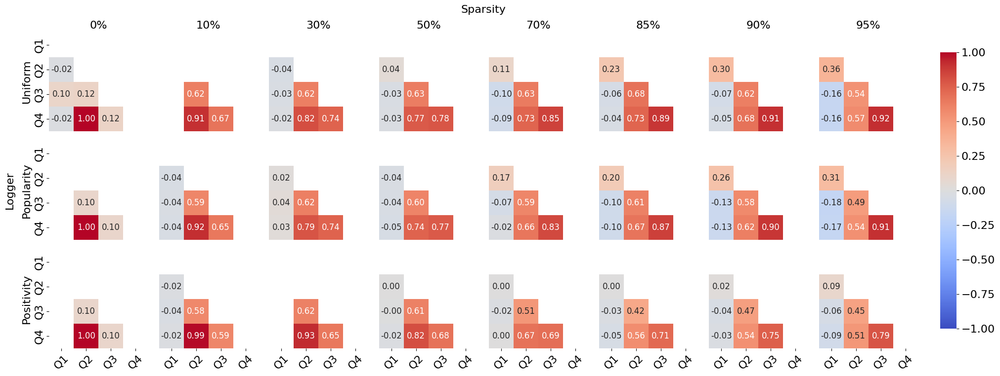

In [ ]:
# Build joint Q1–Q4 dataframe
df_q = build_q1_q4_dataframe(
    q1_dict=q1_tierate_by_biastype_metric_biasmodel_samplerblock,
    q2_dict=q2_kendalldf_by_biastype_metric_biasmodel_samplerblock,
    q3_dict=q3_kendalldf_by_biastype_metric_biasmodel_samplerblock,
    q4_dict=q4_kendalldf_by_biastype_metric_biasmodel_samplerblock,
    bias_types=bias_types,
    metric_name=METRIC_NAME,
    sampler_block="POSITIVITY",
    sampler_name="POSITIVITY@1000"
)

plot_q_correlation_grid(
    df_q,
    bias_types=bias_types,
    percentages_to_plot=[0, 10, 30, 50, 70, 85, 90, 95],
    sampler_name="POSITIVITY@1000",
    method="spearman",
    output_path=".",
    filename="q5_correlation_grid_pos1000.pdf"
)

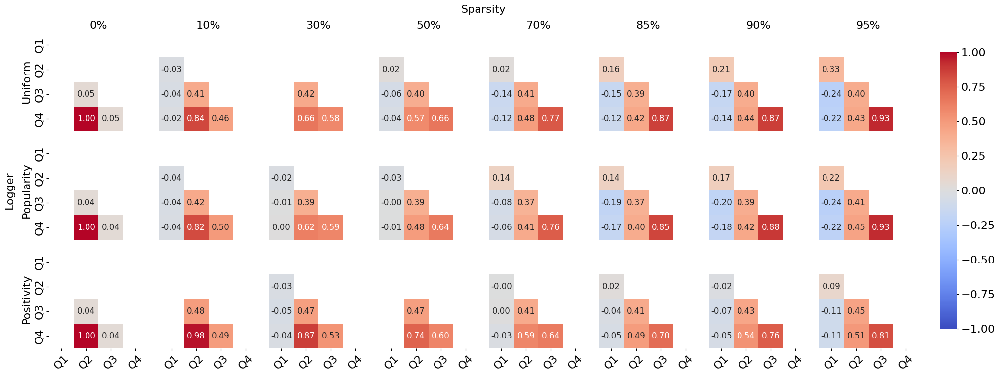

In [ ]:
# Build joint Q1–Q4 dataframe
df_q = build_q1_q4_dataframe(
    q1_dict=q1_tierate_by_biastype_metric_biasmodel_samplerblock,
    q2_dict=q2_kendalldf_by_biastype_metric_biasmodel_samplerblock,
    q3_dict=q3_kendalldf_by_biastype_metric_biasmodel_samplerblock,
    q4_dict=q4_kendalldf_by_biastype_metric_biasmodel_samplerblock,
    bias_types=bias_types,
    metric_name=METRIC_NAME,
    sampler_block="SKEW",
    sampler_name="SKEW@1000"
)

plot_q_correlation_grid(
    df_q,
    bias_types=bias_types,
    percentages_to_plot=[0, 10, 30, 50, 70, 85, 90, 95],
    sampler_name="SKEW@1000",
    method="spearman",
    output_path=".",
    filename="q5_correlation_grid_skew1000.pdf"
)

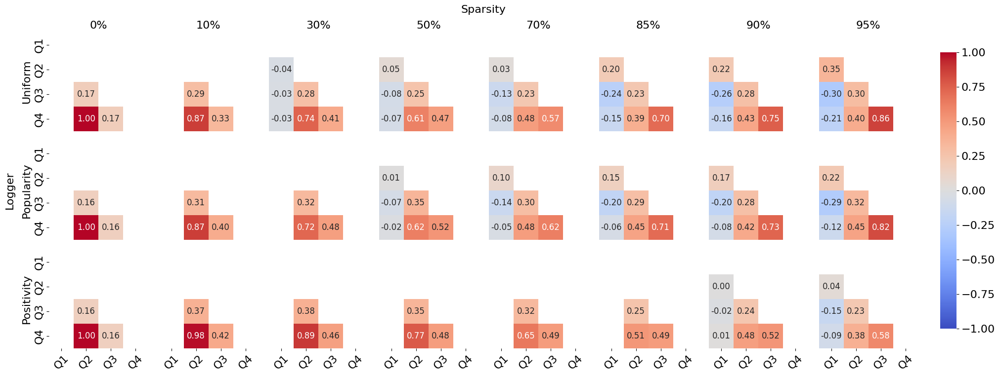

In [ ]:
# Build joint Q1–Q4 dataframe
df_q = build_q1_q4_dataframe(
    q1_dict=q1_tierate_by_biastype_metric_biasmodel_samplerblock,
    q2_dict=q2_kendalldf_by_biastype_metric_biasmodel_samplerblock,
    q3_dict=q3_kendalldf_by_biastype_metric_biasmodel_samplerblock,
    q4_dict=q4_kendalldf_by_biastype_metric_biasmodel_samplerblock,
    bias_types=bias_types,
    metric_name=METRIC_NAME,
    sampler_block="WTD",
    sampler_name="WTD@1000"
)

plot_q_correlation_grid(
    df_q,
    bias_types=bias_types,
    percentages_to_plot=[0, 10, 30, 50, 70, 85, 90, 95],
    sampler_name="WTD@1000",
    method="spearman",
    output_path=".",
    filename="q5_correlation_grid_wtd1000.pdf"
)

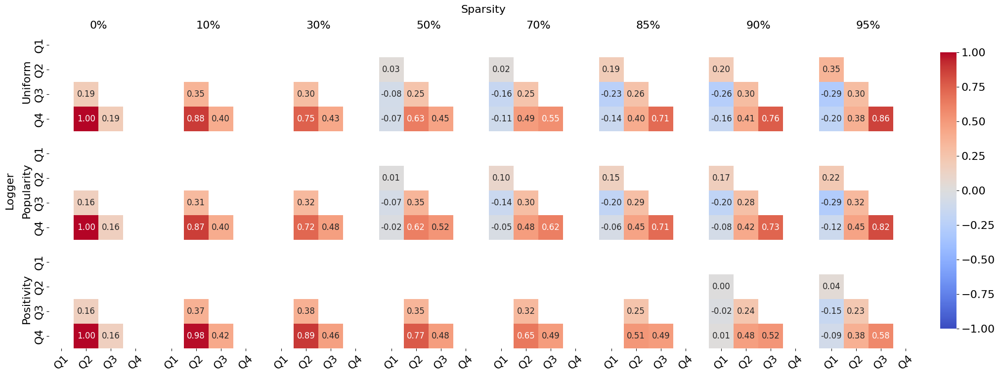

In [ ]:
# Build joint Q1–Q4 dataframe
df_q = build_q1_q4_dataframe(
    q1_dict=q1_tierate_by_biastype_metric_biasmodel_samplerblock,
    q2_dict=q2_kendalldf_by_biastype_metric_biasmodel_samplerblock,
    q3_dict=q3_kendalldf_by_biastype_metric_biasmodel_samplerblock,
    q4_dict=q4_kendalldf_by_biastype_metric_biasmodel_samplerblock,
    bias_types=bias_types,
    metric_name=METRIC_NAME,
    sampler_block="WTDH",
    sampler_name="WTDH@1000"
)

plot_q_correlation_grid(
    df_q,
    bias_types=bias_types,
    percentages_to_plot=[0, 10, 30, 50, 70, 85, 90, 95],
    sampler_name="WTDH@1000",
    method="spearman",
    output_path=".",
    filename="q5_correlation_grid_wtdh1000.pdf"
)